In [1]:
# ==========================================
# PHASE 3 — MELODY-CHORD COMPATIBILITY
# CELL 1: DATASET LOADING
# ==========================================

import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

from IPython.display import display


# ------------------------------------------
# 1. Paths and configuration
# ------------------------------------------

PROJECT_ROOT = Path(
    "/Users/praise/Developer/vocal-harmonization"
)

DATASET_PATH = (
    PROJECT_ROOT
    / "datasets/mtg-jamendo/phase3-prepared"
    / "windows_v2_7family_timing_provisional.jsonl"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "datasets/mtg-jamendo/phase3-prepared"
    / "melody_chord_compatibility"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep the test set untouched during development.
# Set True only when ready for the final dataset audit.

INCLUDE_TEST = False

ALLOWED_SPLITS = (
    {"train", "val", "test"}
    if INCLUDE_TEST
    else {"train", "val"}
)

# Our Phase 3 windows contain 16 bars,
# with an 8-bar stride (50% overlap).

WINDOW_STRIDE_BARS = 8
WINDOW_LENGTH_BARS = 16


# ------------------------------------------
# 2. Chord-tone definitions
# ------------------------------------------

# Intervals are semitones above the chord root.
#
# Example:
# C major = C E G = 0, 4, 7

CHORD_INTERVALS = {
    "maj":       (0, 4, 7),
    "min":       (0, 3, 7),

    "maj7":      (0, 4, 7, 11),
    "min7":      (0, 3, 7, 10),
    "min9":      (0, 2, 3, 7, 10),

    "7":         (0, 4, 7, 10),
    "9":         (0, 2, 4, 7, 10),

    "dim":       (0, 3, 6),
    "dim7":      (0, 3, 6, 9),
    "hdim7":     (0, 3, 6, 10),

    "aug":       (0, 4, 8),

    "sus2":      (0, 2, 7),
    "sus4":      (0, 5, 7),
    "sus4(b7)":  (0, 5, 7, 10)
}

PC_NAMES = [
    "C", "C#", "D", "Eb", "E", "F",
    "F#", "G", "Ab", "A", "Bb", "B"
]


# ------------------------------------------
# 3. Load JSONL
# ------------------------------------------

assert DATASET_PATH.exists(), (
    f"Dataset not found: {DATASET_PATH}"
)

windows = []

with open(DATASET_PATH, "r", encoding="utf-8") as f:

    for line in f:

        if line.strip():

            row = json.loads(line)

            if row.get("split") in ALLOWED_SPLITS:
                windows.append(row)

assert len(windows) > 0


# ------------------------------------------
# 4. Schema helpers
# ------------------------------------------

def first_value(record, *keys, default=None):

    for key in keys:

        if key in record and record[key] is not None:
            return record[key]

    return default


def find_sequence(record, keys):

    for key in keys:

        value = record.get(key)

        if isinstance(value, list):
            return value

        if isinstance(value, dict):

            for inner in [
                "notes", "events", "beats",
                "targets", "items"
            ]:

                nested = value.get(inner)

                if isinstance(nested, list):
                    return nested

    return []


def get_melody_events(record):

    return find_sequence(
        record,
        ["melody_notes", "melody", "notes"]
    )


def get_beat_grid(record):

    return find_sequence(
        record,
        [
            "beat_grid",
            "beat_timing",
            "beats",
            "beat_positions"
        ]
    )


def get_chord_targets(record):

    return find_sequence(
        record,
        [
            "beat_targets",
            "chord_targets",
            "targets"
        ]
    )


# ------------------------------------------
# 5. Inspect dataset
# ------------------------------------------

track_ids = {
    row["track_id"]
    for row in windows
}

print("PHASE 3 — MELODY-CHORD DATASET")
print("--------------------------------")

print("Windows:", len(windows))
print("Unique songs:", len(track_ids))

print("\nSplit distribution:")

display(
    pd.Series(
        [row["split"] for row in windows]
    ).value_counts()
)

sample = windows[0]

print("\nFIRST RECORD STRUCTURE")
print("--------------------------------")

print("Track:", sample.get("track_id"))
print("Window:", sample.get("window_index"))

print("\nTop-level keys:")
print(list(sample.keys()))

melody_sample = get_melody_events(sample)
grid_sample = get_beat_grid(sample)
chord_sample = get_chord_targets(sample)

print("\nMelody events:", len(melody_sample))
print("Beat-grid entries:", len(grid_sample))
print("Chord-target entries:", len(chord_sample))

if melody_sample:
    print("\nExample melody note:")
    print(melody_sample[0])

if grid_sample:
    print("\nExample beat-grid entry:")
    print(grid_sample[0])

if chord_sample:
    print("\nExample chord target:")
    print(chord_sample[0])

print("\nChord qualities supported:")
print(list(CHORD_INTERVALS.keys()))

print("\nTest split included:", INCLUDE_TEST)

print("\nDataset loading completed!")

PHASE 3 — MELODY-CHORD DATASET
--------------------------------
Windows: 7687
Unique songs: 928

Split distribution:


train    6282
val      1405
Name: count, dtype: int64


FIRST RECORD STRUCTURE
--------------------------------
Track: track_0000382
Window: 0

Top-level keys:
['track_id', 'window_index', 'split', 'artist_id', 'reference_key', 'semitone_shift', 'duration_sec', 'window_start_sec', 'genre_vector', 'has_selected_genre', 'melody', 'beat_targets', 'dataset_version', 'quality_flags', 'beat_grid', 'representation']

Melody events: 63
Beat-grid entries: 64
Chord-target entries: 64

Example melody note:
{'onset_sec': 0.0, 'duration_sec': 0.23479, 'midi_pitch': 69, 'pitch_class': 9}

Example beat-grid entry:
{'beat_index': 0, 'time_sec': 0.0, 'duration_sec': 0.47, 'bar_index': 0, 'beat_in_bar': 1, 'meter_numerator': 4, 'is_downbeat': True}

Example chord target:
{'beat_index': 0, 'time_sec': 0.0, 'duration_sec': 0.47, 'root_pc': None, 'quality': None, 'valid_mask': 0, 'target_state': 'N_CANDIDATE', 'root_id': None, 'family': None, 'family_id': None, 'plan_label': 'N.C.', 'model_target_mask': 0, 'family_9': None, 'family_id_9': None, 'plan_label_9':

In [2]:
# ==========================================
# PHASE 3 — MELODY-CHORD COMPATIBILITY
# CELL 2: FULL ANALYSIS
# ==========================================

import numpy as np
import pandas as pd

from collections import Counter


# ==========================================
# 1. Extract normalized melody notes
# ==========================================

def extract_notes(record):

    events = get_melody_events(record)

    notes = []

    for note in events:

        onset = first_value(
            note,
            "onset_sec",
            "time_sec",
            "start_sec"
        )

        duration = first_value(
            note,
            "duration_sec",
            "duration"
        )

        pc = first_value(
            note,
            "normalized_pc",
            "pitch_class",
            "normalized_pitch_class"
        )

        if pc is None:

            midi = first_value(
                note,
                "normalized_midi",
                "midi_pitch"
            )

            if midi is not None:
                pc = int(midi) % 12

        if onset is None or pc is None:
            continue

        if duration is None:

            end = first_value(
                note,
                "end_sec"
            )

            if end is not None:
                duration = float(end) - float(onset)

        if duration is None:
            continue

        onset = float(onset)
        duration = float(duration)

        if duration <= 0:
            continue

        notes.append((
            onset,
            onset + duration,
            int(pc) % 12
        ))

    if not notes:

        return (
            np.array([], dtype=float),
            np.array([], dtype=float),
            np.array([], dtype=int)
        )

    arr = np.asarray(notes)

    return (
        arr[:, 0].astype(float),
        arr[:, 1].astype(float),
        arr[:, 2].astype(int)
    )


# ==========================================
# 2. Extract aligned chord beats
# ==========================================

def extract_chord_beats(record):

    grid = get_beat_grid(record)
    targets = get_chord_targets(record)

    if not grid:
        grid = targets

    if not targets:
        targets = grid

    if not grid or not targets:
        raise ValueError(
            "Beat grid or chord targets unavailable. "
            f"Track: {record.get('track_id')}"
        )

    # Match timing and targets by beat index.

    grid_lookup = {
        int(first_value(g, "beat_index", default=i)): g
        for i, g in enumerate(grid)
    }

    beats = []

    for i, target in enumerate(targets):

        beat_id = int(
            first_value(
                target,
                "beat_index",
                default=i
            )
        )

        timing = grid_lookup.get(beat_id)

        if timing is None:
            raise ValueError(
                f"Missing beat timing: {beat_id}"
            )

        # Timing must come from the beat grid.
        start = first_value(
            timing,
            "time_sec",
            "relative_time_sec",
            "onset_sec",
            "start_sec"
        )

        duration = first_value(
            timing,
            "duration_sec",
            "duration"
        )

        bar = first_value(
            timing,
            "bar_index"
        )

        position = first_value(
            timing,
            "beat_in_bar",
            "beat_position"
        )

        if start is None or bar is None or position is None:

            raise ValueError(
                "Missing beat timing/bar metadata. "
                f"Track: {record.get('track_id')}, "
                f"beat: {beat_id}"
            )

        beats.append({
            "beat_index": beat_id,
            "start": float(start),
            "duration": (
                float(duration)
                if duration is not None
                else None
            ),
            "bar": int(bar),
            "position": int(position),
            "target": target
        })

    beats.sort(key=lambda x: x["beat_index"])

    # Infer missing durations from the next beat.
    # A final beat without a known end is skipped.

    for i, beat in enumerate(beats):

        if beat["duration"] is None:

            if i + 1 < len(beats):

                beat["duration"] = (
                    beats[i + 1]["start"]
                    - beat["start"]
                )

    return beats


# ==========================================
# 3. Analyze individual chord beats
# ==========================================

selected_beats = {}

unsupported_qualities = Counter()

duplicate_observations = 0
chord_disagreements = 0

total_valid_observations = 0
skipped_timing = 0
skipped_missing_window_index = 0


for window in windows:

    track_id = window["track_id"]
    split = window["split"]

    window_index = window.get("window_index")

    if window_index is None:

        skipped_missing_window_index += 1
        continue

    window_index = int(window_index)

    # Melody is already normalized to the
    # Phase 3 reference pitch collection.

    note_starts, note_ends, note_pcs = (
        extract_notes(window)
    )

    beats = extract_chord_beats(window)

    for beat in beats:

        target = beat["target"]

        # ----------------------------------
        # A. Check target reliability
        # ----------------------------------

        state = target.get("target_state")

        if state is not None and state != "CHORD":
            continue

        mask = first_value(
            target,
            "model_target_mask",
            "valid_mask"
        )

        if mask is not None and not bool(mask):
            continue

        root = first_value(
            target,
            "root_id",
            "relative_root_pc",
            "normalized_root_pc"
        )

        quality = first_value(
            target,
            "quality",
            "chord_quality"
        )

        if root is None or quality is None:
            continue

        if pd.isna(root) or pd.isna(quality):
            continue

        quality = str(quality).strip().lower()

        if quality not in CHORD_INTERVALS:

            unsupported_qualities[quality] += 1
            continue

        root = int(root)

        assert 0 <= root < 12

        # ----------------------------------
        # B. Chord timing
        # ----------------------------------

        start = beat["start"]
        duration = beat["duration"]

        if duration is None or duration <= 0:

            skipped_timing += 1
            continue

        end = start + duration

        # ----------------------------------
        # C. Allowed pitch classes
        # ----------------------------------

        chord_pcs = np.array([
            (root + interval) % 12
            for interval in CHORD_INTERVALS[quality]
        ])

        compatible_notes = np.isin(
            note_pcs,
            chord_pcs
        )

        # ----------------------------------
        # D. NOTE COUNT
        # ----------------------------------

        # Count notes whose onset occurs
        # while this chord beat is active.

        onset_mask = (
            (note_starts >= start - 1e-6)
            &
            (note_starts < end - 1e-6)
        )

        onset_count = int(
            onset_mask.sum()
        )

        onset_correct = int(
            (onset_mask & compatible_notes).sum()
        )

        onset_wrong = (
            onset_count - onset_correct
        )

        # ----------------------------------
        # E. DURATION ANALYSIS
        # ----------------------------------

        # A sustained note can overlap
        # several different chord beats.
        #
        # Measure only its duration within
        # the current chord beat.

        overlap = np.maximum(
            0.0,
            np.minimum(note_ends, end)
            -
            np.maximum(note_starts, start)
        )

        correct_duration = float(
            overlap[compatible_notes].sum()
        )

        wrong_duration = float(
            overlap[~compatible_notes].sum()
        )

        total_duration = (
            correct_duration + wrong_duration
        )

        # ----------------------------------
        # F. Remove window overlap
        # ----------------------------------

        local_bar = beat["bar"]

        # In the Phase 3 dataset each
        # 16-bar window advances by 8 bars.
        #
        # Most saved windows use local
        # bar indices 0–15.

        if 0 <= local_bar < WINDOW_LENGTH_BARS:

            global_bar = (
                window_index * WINDOW_STRIDE_BARS
                +
                local_bar
            )

            # Prefer observations located
            # farther from window boundaries.

            centrality = min(
                local_bar,
                WINDOW_LENGTH_BARS - 1 - local_bar
            )

        else:

            # Already-absolute bar indices.
            global_bar = local_bar
            centrality = 0

        key = (
            track_id,
            global_bar,
            beat["position"]
        )

        total_valid_observations += 1

        observation = {
            "track_id": track_id,
            "split": split,

            "global_bar": global_bar,
            "beat_position": beat["position"],

            "root": root,
            "quality": quality,

            "chord": (
                f"{PC_NAMES[root]}:{quality}"
            ),

            "note_count": onset_count,
            "correct_notes": onset_correct,
            "wrong_notes": onset_wrong,

            "total_note_sec": total_duration,
            "correct_sec": correct_duration,
            "wrong_sec": wrong_duration,

            "_priority": centrality
        }

        previous = selected_beats.get(key)

        if previous is not None:

            duplicate_observations += 1

            if (
                previous["root"] != root
                or
                previous["quality"] != quality
            ):
                chord_disagreements += 1

            if centrality > previous["_priority"]:
                selected_beats[key] = observation

        else:

            selected_beats[key] = observation


# ==========================================
# 4. Verify deduplication
# ==========================================

if skipped_missing_window_index:
    raise ValueError(
        "Some windows have no window_index; "
        "deduplication is not reliable."
    )

if unsupported_qualities:
    raise ValueError(
        "Unsupported chord qualities: "
        f"{dict(unsupported_qualities)}"
    )

if not selected_beats:
    raise ValueError(
        "No valid chord beats were found. "
        "Check the field names printed in Cell 1."
    )

beat_df = pd.DataFrame(
    selected_beats.values()
).drop(columns="_priority")


print("MELODY-CHORD ALIGNMENT")
print("--------------------------------")

print(
    "Valid beat observations before deduplication:",
    total_valid_observations
)

print(
    "Duplicate observations:",
    duplicate_observations
)

print(
    "Unique valid chord beats:",
    len(beat_df)
)

print(
    "Conflicting duplicate chord labels:",
    chord_disagreements
)

print(
    "Beats skipped for missing duration:",
    skipped_timing
)

if duplicate_observations == 0:

    print(
        "\nWARNING: No overlap duplicates detected. "
        "Verify the global-bar mapping."
    )

elif chord_disagreements > 0:

    print(
        "\nWARNING: Some overlapping windows "
        "disagree on chord labels. "
        "Review before interpreting results."
    )


# ==========================================
# 5. Aggregate song-level statistics
# ==========================================

SUM_COLUMNS = [
    "note_count",
    "correct_notes",
    "wrong_notes",
    "total_note_sec",
    "correct_sec",
    "wrong_sec"
]

song_df = (
    beat_df
    .groupby(
        ["split", "track_id"],
        as_index=False
    )[SUM_COLUMNS]
    .sum()
)

song_df["note_match_pct"] = (
    100
    * song_df["correct_notes"]
    / song_df["note_count"].replace(0, np.nan)
)

song_df["duration_match_pct"] = (
    100
    * song_df["correct_sec"]
    / song_df["total_note_sec"].replace(0, np.nan)
)


# ==========================================
# 6. Minimum evidence requirements
# ==========================================

# A song with just two notes should not
# receive the same importance as a song
# with hundreds of evaluated notes.
#
# These thresholds can be changed.

MIN_EVALUATED_NOTES = 20
MIN_EVALUATED_DURATION = 5.0

song_df["eligible"] = (
    (song_df["note_count"] >= MIN_EVALUATED_NOTES)
    &
    (
        song_df["total_note_sec"]
        >= MIN_EVALUATED_DURATION
    )
)

eligible_songs = song_df[
    song_df["eligible"]
].copy()


# ==========================================
# 7. Overall dataset statistics
# ==========================================

total_notes = int(
    beat_df["note_count"].sum()
)

correct_notes = int(
    beat_df["correct_notes"].sum()
)

wrong_notes = int(
    beat_df["wrong_notes"].sum()
)

total_duration = float(
    beat_df["total_note_sec"].sum()
)

correct_duration = float(
    beat_df["correct_sec"].sum()
)

wrong_duration = float(
    beat_df["wrong_sec"].sum()
)

print("\nOVERALL DATASET COMPATIBILITY")
print("--------------------------------")

print("Songs analyzed:", len(song_df))
print("Songs meeting minimum evidence:", len(eligible_songs))

print("\nNOTE COUNT")
print("--------------------------------")

print("Evaluated note onsets:", total_notes)
print("Matching notes:", correct_notes)
print("Nonmatching notes:", wrong_notes)

print(
    "Note compatibility:",
    f"{100 * correct_notes / total_notes:.2f}%"
)

print("\nDURATION")
print("--------------------------------")

print(
    "Total evaluated note-seconds:",
    round(total_duration, 2)
)

print(
    "Matching note-seconds:",
    round(correct_duration, 2)
)

print(
    "Nonmatching note-seconds:",
    round(wrong_duration, 2)
)

print(
    "Duration compatibility:",
    f"{100 * correct_duration / total_duration:.2f}%"
)


# ==========================================
# 8. SONG THRESHOLD ANALYSIS
# ==========================================

threshold_rows = []

for threshold in [50, 80]:

    note_pass = (
        eligible_songs["note_match_pct"]
        >= threshold
    )

    duration_pass = (
        eligible_songs["duration_match_pct"]
        >= threshold
    )

    both_pass = (
        note_pass & duration_pass
    )

    n = len(eligible_songs)

    threshold_rows.append({
        "Threshold": f">= {threshold}%",

        "Eligible songs": n,

        "Songs passing note count":
            int(note_pass.sum()),

        "Note pass percentage":
            100 * note_pass.mean(),

        "Songs passing duration":
            int(duration_pass.sum()),

        "Duration pass percentage":
            100 * duration_pass.mean(),

        "Songs passing both":
            int(both_pass.sum()),

        "Both pass percentage":
            100 * both_pass.mean()
    })


threshold_df = pd.DataFrame(
    threshold_rows
)

print("\nSONG COMPATIBILITY THRESHOLDS")
print("--------------------------------")

display(
    threshold_df.round(2)
)


# ==========================================
# 9. Summary by dataset split
# ==========================================

split_rows = []

for split, group in beat_df.groupby("split"):

    split_rows.append({
        "Split": split,

        "Songs":
            song_df[
                song_df["split"] == split
            ]["track_id"].nunique(),

        "Evaluated notes":
            int(group["note_count"].sum()),

        "Note match %":
            100
            * group["correct_notes"].sum()
            / group["note_count"].sum(),

        "Duration match %":
            100
            * group["correct_sec"].sum()
            / group["total_note_sec"].sum()
    })


split_df = pd.DataFrame(
    split_rows
)

print("\nCOMPATIBILITY BY SPLIT")
print("--------------------------------")

display(split_df.round(2))


# ==========================================
# 10. CHORD QUALITY ANALYSIS
# ==========================================

quality_df = (
    beat_df
    .groupby("quality", as_index=False)[SUM_COLUMNS]
    .sum()
)

quality_df["note_match_pct"] = (
    100
    * quality_df["correct_notes"]
    / quality_df["note_count"].replace(0, np.nan)
)

quality_df["duration_match_pct"] = (
    100
    * quality_df["correct_sec"]
    / quality_df["total_note_sec"].replace(0, np.nan)
)

quality_df = quality_df.sort_values(
    "note_count",
    ascending=False
)

print("\nCOMPATIBILITY BY CHORD QUALITY")
print("--------------------------------")

display(
    quality_df[
        [
            "quality",
            "note_count",
            "note_match_pct",
            "duration_match_pct"
        ]
    ].round(2)
)


# ==========================================
# 11. INDIVIDUAL CHORD ANALYSIS
# ==========================================

chord_df = (
    beat_df
    .groupby("chord", as_index=False)[SUM_COLUMNS]
    .sum()
)

chord_df["note_match_pct"] = (
    100
    * chord_df["correct_notes"]
    / chord_df["note_count"].replace(0, np.nan)
)

chord_df["duration_match_pct"] = (
    100
    * chord_df["correct_sec"]
    / chord_df["total_note_sec"].replace(0, np.nan)
)

chord_df = chord_df.sort_values(
    "note_count",
    ascending=False
)

print("\nMOST FREQUENT CHORDS")
print("--------------------------------")

display(
    chord_df[
        [
            "chord",
            "note_count",
            "note_match_pct",
            "duration_match_pct"
        ]
    ].head(20).round(2)
)


# ==========================================
# 12. SONG-BY-CHORD ANALYSIS
# ==========================================

song_chord_df = (
    beat_df
    .groupby(
        ["split", "track_id", "chord"],
        as_index=False
    )[SUM_COLUMNS]
    .sum()
)

song_chord_df["note_match_pct"] = (
    100
    * song_chord_df["correct_notes"]
    / song_chord_df["note_count"].replace(0, np.nan)
)

song_chord_df["duration_match_pct"] = (
    100
    * song_chord_df["correct_sec"]
    / song_chord_df["total_note_sec"].replace(0, np.nan)
)


# ==========================================
# 13. Display song rankings
# ==========================================

print("\nTOP 20 COMPATIBLE SONGS")
print("--------------------------------")

display(
    eligible_songs[
        [
            "track_id",
            "split",
            "note_count",
            "note_match_pct",
            "duration_match_pct"
        ]
    ]
    .sort_values(
        "note_match_pct",
        ascending=False
    )
    .head(20)
    .round(2)
)

print("\nBOTTOM 20 COMPATIBLE SONGS")
print("--------------------------------")

display(
    eligible_songs[
        [
            "track_id",
            "split",
            "note_count",
            "note_match_pct",
            "duration_match_pct"
        ]
    ]
    .sort_values(
        "note_match_pct",
        ascending=True
    )
    .head(20)
    .round(2)
)


# ==========================================
# 14. Save results
# ==========================================

song_df.to_csv(
    OUTPUT_DIR / "song_compatibility.csv",
    index=False
)

song_chord_df.to_csv(
    OUTPUT_DIR / "song_chord_compatibility.csv",
    index=False
)

quality_df.to_csv(
    OUTPUT_DIR / "chord_quality_compatibility.csv",
    index=False
)

chord_df.to_csv(
    OUTPUT_DIR / "individual_chord_compatibility.csv",
    index=False
)

threshold_df.to_csv(
    OUTPUT_DIR / "song_threshold_summary.csv",
    index=False
)

split_df.to_csv(
    OUTPUT_DIR / "split_compatibility.csv",
    index=False
)


# ==========================================
# 15. Final summary
# ==========================================

print("\nFINAL ANALYSIS SUMMARY")
print("--------------------------------")

print("Songs analyzed:", len(song_df))
print("Unique chord beats:", len(beat_df))
print("Evaluated melody note onsets:", total_notes)

print(
    "Overall note compatibility:",
    f"{100 * correct_notes / total_notes:.2f}%"
)

print(
    "Overall duration compatibility:",
    f"{100 * correct_duration / total_duration:.2f}%"
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nOriginal dataset modified: NO")
print("Transformer training performed: NO")
print("Test split included:", INCLUDE_TEST)

print("\nMelody-chord compatibility analysis completed!")

MELODY-CHORD ALIGNMENT
--------------------------------
Valid beat observations before deduplication: 410388
Duplicate observations: 166767
Unique valid chord beats: 243621
Conflicting duplicate chord labels: 11563
Beats skipped for missing duration: 0


OVERALL DATASET COMPATIBILITY
--------------------------------
Songs analyzed: 928
Songs meeting minimum evidence: 926

NOTE COUNT
--------------------------------
Evaluated note onsets: 285877
Matching notes: 162082
Nonmatching notes: 123795
Note compatibility: 56.70%

DURATION
--------------------------------
Total evaluated note-seconds: 103746.19
Matching note-seconds: 64478.63
Nonmatching note-seconds: 39267.56
Duration compatibility: 62.15%

SONG COMPATIBILITY THRESHOLDS
--------------------------------


,Threshold,Eligible songs,Songs passing note count,Note pass percentage,Songs passing duration,Duration pass percentage,Songs passing both,Both pass percentage
0,>= 50%,926,705,76.13,800,86.39,692,74.73
1,>= 80%,926,19,2.05,34,3.67,14,1.51



COMPATIBILITY BY SPLIT
--------------------------------


,Split,Songs,Evaluated notes,Note match %,Duration match %
0,train,752,232274,57.04,62.54
1,val,176,53603,55.20,60.49



COMPATIBILITY BY CHORD QUALITY
--------------------------------


...


TOP 20 COMPATIBLE SONGS
--------------------------------


,track_id,split,note_count,note_match_pct,duration_match_pct
539,track_1132805,train,117,93.16,93.94
764,track_0205077,val,243,92.59,91.43
536,track_1132794,train,48,89.58,95.93
661,track_1160648,train,63,88.89,86.68
580,track_1137258,train,112,86.61,90.32
162,track_0659901,train,246,86.59,93.07
207,track_0938389,train,133,86.47,88.73
127,track_0571477,train,263,85.17,89.43
633,track_1159859,train,140,85.00,79.81
751,track_1419770,train,50,84.00,55.78



BOTTOM 20 COMPATIBLE SONGS
--------------------------------


,track_id,split,note_count,note_match_pct,duration_match_pct
161,track_0659900,train,115,21.74,34.74
478,track_1114506,train,25,28.00,46.54
854,track_1012601,val,149,28.19,30.51
121,track_0565795,train,285,29.12,32.91
821,track_0915578,val,78,29.49,36.30
496,track_1124712,train,40,30.00,72.26
742,track_1400599,train,154,31.17,41.13
855,track_1012602,val,143,32.17,38.84
779,track_0230830,val,221,32.58,41.21
67,track_0345140,train,209,33.01,41.18



FINAL ANALYSIS SUMMARY
--------------------------------
Songs analyzed: 928
Unique chord beats: 243621
Evaluated melody note onsets: 285877
Overall note compatibility: 56.70%
Overall duration compatibility: 62.15%

Output directory:
/Users/praise/Developer/vocal-harmonization/datasets/mtg-jamendo/phase3-prepared/melody_chord_compatibility

Original dataset modified: NO
Transformer training performed: NO
Test split included: False

Melody-chord compatibility analysis completed!


In [3]:
# ==========================================
# MELODY-CHORD COMPATIBILITY THRESHOLDS
# ==========================================

thresholds = [50, 60, 70, 80, 90]

results = []

for t in thresholds:

    note_pass = eligible_songs["note_match_pct"] >= t
    duration_pass = eligible_songs["duration_match_pct"] >= t
    both_pass = note_pass & duration_pass

    results.append({
        "Threshold": f">= {t}%",
        "Songs (Notes)": note_pass.sum(),
        "Notes %": round(note_pass.mean() * 100, 2),
        "Songs (Duration)": duration_pass.sum(),
        "Duration %": round(duration_pass.mean() * 100, 2),
        "Songs (Both)": both_pass.sum(),
        "Both %": round(both_pass.mean() * 100, 2)
    })

threshold_analysis = pd.DataFrame(results)

print("SONG COMPATIBILITY THRESHOLDS")
print("--------------------------------")

display(threshold_analysis)

SONG COMPATIBILITY THRESHOLDS
--------------------------------


,Threshold,Songs (Notes),Notes %,Songs (Duration),Duration %,Songs (Both),Both %
0,>= 50%,705,76.13,800,86.39,692,74.73
1,>= 60%,304,32.83,528,57.02,284,30.67
2,>= 70%,87,9.40,198,21.38,75,8.10
3,>= 80%,19,2.05,34,3.67,14,1.51
4,>= 90%,2,0.22,7,0.76,2,0.22


In [4]:
# ============================================================
# PHASE 3 EXPERIMENT
# FLAT 84-CLASS TRANSFORMER — BOTH COMPATIBILITY >= 60%
# Standard attention, no temporal bias
# ============================================================

import json
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path(
    "/Users/praise/Developer/vocal-harmonization"
)

DATASET_PATH = (
    ROOT /
    "datasets/mtg-jamendo/phase3-prepared/"
    "windows_v2_7family_timing_provisional.jsonl"
)

COMPATIBILITY_PATH = (
    ROOT /
    "datasets/mtg-jamendo/phase3-prepared/"
    "melody_chord_compatibility/song_compatibility.csv"
)

SAVE_DIR = ROOT / "experiments/pasan/checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENT = "flat84_compatibility_both60_standard"

BEST_PATH = SAVE_DIR / f"{EXPERIMENT}_best.pt"
HISTORY_PATH = SAVE_DIR / f"{EXPERIMENT}_history.csv"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_ROOTS = 12
NUM_FAMILIES = 7
NUM_CLASSES = 84

IGNORE_INDEX = -100

D_MODEL = 128
NHEAD = 4
ENC_LAYERS = 2
DEC_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.1

BATCH_SIZE = 16
LR = 3e-4
WEIGHT_DECAY = 0.01
MAX_EPOCHS = 25
PATIENCE = 10

print("EXPERIMENT CONFIGURATION")
print("-" * 55)
print("Experiment:", EXPERIMENT)
print("Device:", DEVICE)
print("Classes:", NUM_CLASSES)
print("Temporal bias: DISABLED")
print("Genre conditioning: DISABLED")
print("Test dataset: LOCKED")


# ============================================================
# 2. SELECT HIGH-COMPATIBILITY SONGS
# ============================================================

compat = pd.read_csv(COMPATIBILITY_PATH)

selected = compat[
    (compat["note_count"] >= 20) &
    (compat["total_note_sec"] >= 5.0) &
    (compat["note_match_pct"] >= 60.0) &
    (compat["duration_match_pct"] >= 60.0)
].copy()

selected_ids = set(selected["track_id"].astype(str))

print("\nSONG SELECTION")
print("-" * 55)

print("Selected songs:", len(selected_ids))

print(
    selected.groupby("split")["track_id"].nunique()
)

assert len(selected_ids) == 284, (
    f"Expected 284 songs; found {len(selected_ids)}."
)

assert set(selected["split"]) <= {"train", "val"}

# Save exact selection for reproducibility.
selected.to_csv(
    SAVE_DIR / f"{EXPERIMENT}_selected_songs.csv",
    index=False
)


# ============================================================
# 3. LOAD FILTERED PHASE 3 WINDOWS
# ============================================================

raw_windows = []

with open(DATASET_PATH, "r", encoding="utf-8") as f:

    for line in f:

        if not line.strip():
            continue

        row = json.loads(line)

        if (
            row["track_id"] in selected_ids
            and row["split"] in ("train", "val")
        ):
            raw_windows.append(row)

train_raw = [
    x for x in raw_windows
    if x["split"] == "train"
]

val_raw = [
    x for x in raw_windows
    if x["split"] == "val"
]

assert train_raw and val_raw

train_tracks = {x["track_id"] for x in train_raw}
val_tracks = {x["track_id"] for x in val_raw}

train_artists = {x["artist_id"] for x in train_raw}
val_artists = {x["artist_id"] for x in val_raw}

assert train_tracks.isdisjoint(val_tracks)
assert train_artists.isdisjoint(val_artists)

assert train_tracks | val_tracks == selected_ids

print("\nFILTERED DATASET")
print("-" * 55)

print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))

print("Training windows:", len(train_raw))
print("Validation windows:", len(val_raw))

print("Artist overlap:", len(train_artists & val_artists))


# ============================================================
# 4. PREPARE MELODY AND CHORD TARGETS
# ============================================================

def prepare_window(row):

    notes = sorted(
        row["melody"],
        key=lambda n: n["onset_sec"]
    )

    beats = row["beat_grid"]
    chords = row["beat_targets"]

    assert len(beats) == len(chords)

    if not notes:
        return None

    # Use the observed beat period to normalize time.
    # This reduces tempo-dependent input scaling.

    durations = [
        float(b["duration_sec"])
        for b in beats
        if float(b["duration_sec"]) > 0
    ]

    beat_period = float(np.median(durations))

    assert beat_period > 0

    first_time = float(beats[0]["time_sec"])

    # -----------------------------
    # Melody features
    # -----------------------------

    note_pc = []
    note_numeric = []

    for n in notes:

        pc = int(n["pitch_class"]) % 12
        midi = float(n["midi_pitch"])

        onset = float(n["onset_sec"]) - first_time
        duration = float(n["duration_sec"])

        note_pc.append(pc)

        note_numeric.append([
            (onset / beat_period) / 100.0,
            min(duration / beat_period, 8.0) / 8.0,
            midi / 127.0
        ])

    # -----------------------------
    # Beat-query features
    # -----------------------------

    beat_numeric = []
    bar_ids = []
    beat_positions = []
    meter_ids = []

    targets = []

    for beat, chord in zip(beats, chords):

        assert (
            int(beat["beat_index"])
            == int(chord["beat_index"])
        )

        t = float(beat["time_sec"]) - first_time
        duration = float(beat["duration_sec"])

        beat_numeric.append([
            (t / beat_period) / 100.0,
            min(duration / beat_period, 8.0) / 8.0
        ])

        bar_ids.append(
            int(beat["bar_index"])
        )

        beat_positions.append(
            int(beat["beat_in_bar"])
        )

        meter_ids.append(
            int(beat["meter_numerator"])
        )

        # Flat joint label:
        # root_id * 7 + family_id

        valid = bool(
            chord.get("model_target_mask", 0)
        )

        root = chord.get("root_id")
        family = chord.get("family_id")

        if (
            valid
            and chord.get("target_state") == "CHORD"
            and root is not None
            and family is not None
        ):

            root = int(root)
            family = int(family)

            assert 0 <= root < 12
            assert 0 <= family < 7

            label = root * 7 + family

        else:

            label = IGNORE_INDEX

        targets.append(label)

    return {
        "note_pc": torch.tensor(
            note_pc, dtype=torch.long
        ),

        "note_numeric": torch.tensor(
            note_numeric, dtype=torch.float32
        ),

        "beat_numeric": torch.tensor(
            beat_numeric, dtype=torch.float32
        ),

        "bar": torch.tensor(
            bar_ids, dtype=torch.long
        ),

        "position": torch.tensor(
            beat_positions, dtype=torch.long
        ),

        "meter": torch.tensor(
            meter_ids, dtype=torch.long
        ),

        "target": torch.tensor(
            targets, dtype=torch.long
        )
    }


train_data = [
    x for row in train_raw
    if (x := prepare_window(row)) is not None
]

val_data = [
    x for row in val_raw
    if (x := prepare_window(row)) is not None
]

assert len(train_data) == len(train_raw)
assert len(val_data) == len(val_raw)


# ============================================================
# 5. DATASET AND PADDING
# ============================================================

class HarmonyDataset(Dataset):

    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


def collate_fn(items):

    result = {}

    keys = [
        "note_pc",
        "note_numeric",
        "beat_numeric",
        "bar",
        "position",
        "meter",
        "target"
    ]

    for key in keys:

        padding = (
            IGNORE_INDEX if key == "target" else 0
        )

        result[key] = pad_sequence(
            [x[key] for x in items],
            batch_first=True,
            padding_value=padding
        )

    note_lengths = torch.tensor([
        len(x["note_pc"]) for x in items
    ])

    beat_lengths = torch.tensor([
        len(x["target"]) for x in items
    ])

    result["note_pad"] = (
        torch.arange(result["note_pc"].shape[1])[None, :]
        >= note_lengths[:, None]
    )

    result["beat_pad"] = (
        torch.arange(result["target"].shape[1])[None, :]
        >= beat_lengths[:, None]
    )

    return result


loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    HarmonyDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    generator=loader_generator
)

val_loader = DataLoader(
    HarmonyDataset(val_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)


# ============================================================
# 6. CLASS DISTRIBUTION AND BALANCING
# ============================================================

train_labels = torch.cat([
    x["target"][x["target"] != IGNORE_INDEX]
    for x in train_data
])

val_labels = torch.cat([
    x["target"][x["target"] != IGNORE_INDEX]
    for x in val_data
])

class_counts = torch.bincount(
    train_labels,
    minlength=NUM_CLASSES
).float()

seen = class_counts > 0

# Inverse square-root frequency weighting.
# Rare classes receive more weight.
# Cap weights to prevent extreme gradients.

class_weights = torch.zeros(NUM_CLASSES)

class_weights[seen] = (
    class_counts[seen].sum()
    / class_counts[seen]
).sqrt()

frequencies = class_counts / class_counts.sum()

class_weights[seen] /= (
    class_weights[seen] * frequencies[seen]
).sum()

class_weights[seen] = class_weights[seen].clamp(
    min=0.5,
    max=4.0
)

class_weights[seen] /= (
    class_weights[seen] * frequencies[seen]
).sum()

class_weights = class_weights.to(DEVICE)

print("\nCLASS DISTRIBUTION")
print("-" * 55)

print("Training targets:", len(train_labels))
print("Validation targets:", len(val_labels))

print("Classes present in training:", int(seen.sum()))

print(
    "Classes present in validation:",
    int(torch.unique(val_labels).numel())
)

unseen_val = ~seen[val_labels]

print(
    "Validation targets with unseen train classes:",
    int(unseen_val.sum())
)

print(
    "Class weight range:",
    round(class_weights[seen].min().item(), 3),
    "to",
    round(class_weights[seen].max().item(), 3)
)


# ============================================================
# 7. STANDARD NON-AUTOREGRESSIVE TRANSFORMER
# ============================================================

class FlatHarmonyTransformer(nn.Module):

    def __init__(self):

        super().__init__()

        # Melody embeddings

        self.pitch_embedding = nn.Embedding(
            12, D_MODEL
        )

        self.note_numeric_embedding = nn.Sequential(
            nn.Linear(3, D_MODEL),
            nn.GELU(),
            nn.Linear(D_MODEL, D_MODEL)
        )

        # Beat query embeddings

        self.bar_embedding = nn.Embedding(
            32, D_MODEL
        )

        self.position_embedding = nn.Embedding(
            17, D_MODEL
        )

        self.meter_embedding = nn.Embedding(
            17, D_MODEL
        )

        self.beat_numeric_embedding = nn.Sequential(
            nn.Linear(2, D_MODEL),
            nn.GELU(),
            nn.Linear(D_MODEL, D_MODEL)
        )

        self.note_norm = nn.LayerNorm(D_MODEL)
        self.beat_norm = nn.LayerNorm(D_MODEL)

        # Standard Transformer encoder

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=FF_DIM,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=ENC_LAYERS,
            enable_nested_tensor=False
        )

        # Standard Transformer decoder
        # No temporal cross-attention bias.
        # No causal mask.
        # No previous chord input.

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=FF_DIM,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=DEC_LAYERS
        )

        # ONE classification head.
        # Direct flat 84-class output.

        self.output_head = nn.Linear(
            D_MODEL,
            NUM_CLASSES
        )

    def forward(self, batch):

        melody = (
            self.pitch_embedding(batch["note_pc"])
            +
            self.note_numeric_embedding(
                batch["note_numeric"]
            )
        )

        melody = self.note_norm(melody)

        encoded = self.encoder(
            melody,
            src_key_padding_mask=batch["note_pad"]
        )

        queries = (
            self.bar_embedding(
                batch["bar"].clamp(0, 31)
            )
            +
            self.position_embedding(
                batch["position"].clamp(0, 16)
            )
            +
            self.meter_embedding(
                batch["meter"].clamp(0, 16)
            )
            +
            self.beat_numeric_embedding(
                batch["beat_numeric"]
            )
        )

        queries = self.beat_norm(queries)

        decoded = self.decoder(
            tgt=queries,
            memory=encoded,
            tgt_key_padding_mask=batch["beat_pad"],
            memory_key_padding_mask=batch["note_pad"]
        )

        return self.output_head(decoded)


model = FlatHarmonyTransformer().to(DEVICE)

parameter_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nMODEL ARCHITECTURE")
print("-" * 55)

print("Architecture: Encoder–Decoder Transformer")
print("Attention: Standard")
print("Output classes:", NUM_CLASSES)
print("Trainable parameters:", f"{parameter_count:,}")

# Verify output and gradient flow.

probe = next(iter(train_loader))

probe = {
    k: v.to(DEVICE)
    for k, v in probe.items()
}

probe_logits = model(probe)

assert probe_logits.shape == (
    probe["target"].shape[0],
    probe["target"].shape[1],
    NUM_CLASSES
)

assert torch.isfinite(probe_logits).all()

print("Forward-pass verification: PASSED")


# ============================================================
# 8. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 9. TRAINING FUNCTION
# ============================================================

def train_epoch():

    model.train()

    loss_sum = 0.0
    weight_sum = 0.0

    for batch in train_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]
        valid = targets != IGNORE_INDEX

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch)

        loss = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            weight=class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        denominator = class_weights[
            targets[valid]
        ].sum().item()

        loss_sum += loss.item() * denominator
        weight_sum += denominator

    return loss_sum / weight_sum


# ============================================================
# 10. VALIDATION METRICS
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    total_loss = 0.0
    total = 0

    root_correct = 0
    family_correct = 0
    joint_correct = 0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.long
    )

    true_changes = 0
    predicted_changes = 0
    detected_changes = 0
    correct_transition_pairs = 0
    valid_pairs_total = 0

    for batch in val_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]

        logits = model(batch)
        predictions = logits.argmax(dim=-1)

        valid = targets != IGNORE_INDEX

        n_valid = int(valid.sum())

        total_loss += F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        ).item()

        total += n_valid

        y = targets[valid]
        p = predictions[valid]

        joint_correct += int((p == y).sum())

        root_correct += int(
            ((p // NUM_FAMILIES) ==
             (y // NUM_FAMILIES)).sum()
        )

        family_correct += int(
            ((p % NUM_FAMILIES) ==
             (y % NUM_FAMILIES)).sum()
        )

        # Confusion matrix

        indices = y * NUM_CLASSES + p

        confusion += torch.bincount(
            indices,
            minlength=NUM_CLASSES ** 2
        ).reshape(
            NUM_CLASSES,
            NUM_CLASSES
        ).cpu()

        # Exact chord-transition metrics.
        # Only adjacent pairs with valid labels.

        pair_valid = (
            valid[:, :-1] & valid[:, 1:]
        )

        ref_change = (
            pair_valid &
            (targets[:, :-1] != targets[:, 1:])
        )

        pred_change = (
            pair_valid &
            (predictions[:, :-1] != predictions[:, 1:])
        )

        true_changes += int(ref_change.sum())
        predicted_changes += int(pred_change.sum())
        detected_changes += int(
            (ref_change & pred_change).sum()
        )
        valid_pairs_total += int(pair_valid.sum())

        correct_transition_pairs += int((
            ref_change
            & (predictions[:, :-1] == targets[:, :-1])
            & (predictions[:, 1:] == targets[:, 1:])
        ).sum())

    # Macro-F1 across validation-supported classes.

    tp = confusion.diag().float()
    support = confusion.sum(dim=1).float()
    predicted_support = confusion.sum(dim=0).float()

    class_f1 = (
        2 * tp /
        (support + predicted_support).clamp(min=1)
    )

    macro_f1 = (
        class_f1[support > 0].mean().item()
    )

    change_f1 = (
        2 * detected_changes /
        max(1, true_changes + predicted_changes)
    )

    return {
        "val_loss": total_loss / total,

        "joint_accuracy": joint_correct / total,
        "root_accuracy": root_correct / total,
        "family_accuracy": family_correct / total,

        "macro_f1": macro_f1,

        "change_f1": change_f1,

        "transition_pair_accuracy":
            correct_transition_pairs /
            max(1, true_changes),

        "true_change_rate":
            true_changes / max(1, valid_pairs_total),

        "predicted_change_rate":
            predicted_changes / max(1, valid_pairs_total),

        "valid_targets": total,

        "supported_classes":
            int((support > 0).sum())
    }


# ============================================================
# 11. MAJORITY-CLASS BASELINE
# ============================================================

majority_class = int(
    torch.bincount(
        train_labels,
        minlength=NUM_CLASSES
    ).argmax()
)

majority_accuracy = (
    (val_labels == majority_class)
    .float()
    .mean()
    .item()
)

print("\nMAJORITY CHORD BASELINE")
print("-" * 55)

print("Most frequent training class:", majority_class)

print(
    "Validation majority accuracy:",
    f"{majority_accuracy:.4f}"
)


# ============================================================
# 12. TRAINING LOOP
# ============================================================

history = []

best_loss = float("inf")
best_epoch = 0
patience_counter = 0

print("\nTRAINING STARTED")
print("=" * 85)

for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    train_loss = train_epoch()
    metrics = validate()

    elapsed = time.perf_counter() - start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        **metrics,
        "seconds": elapsed
    }

    history.append(row)

    improved = metrics["val_loss"] < best_loss - 1e-4

    if improved:

        best_loss = metrics["val_loss"]
        best_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "metrics": metrics,
            "class_counts": class_counts,
            "class_weights": class_weights.cpu(),
            "majority_class": majority_class,
            "seed": SEED,
            "experiment": EXPERIMENT,
            "selected_tracks": sorted(selected_ids),
            "architecture": {
                "d_model": D_MODEL,
                "heads": NHEAD,
                "encoder_layers": ENC_LAYERS,
                "decoder_layers": DEC_LAYERS,
                "ff_dim": FF_DIM,
                "dropout": DROPOUT,
                "num_classes": NUM_CLASSES,
                "temporal_bias": False,
                "genre_conditioning": False
            }
        }, BEST_PATH)

    else:
        patience_counter += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.4f} | "
        f"Val {metrics['val_loss']:.4f} | "
        f"Joint {metrics['joint_accuracy']:.4f} | "
        f"Root {metrics['root_accuracy']:.4f} | "
        f"Family {metrics['family_accuracy']:.4f} | "
        f"Macro-F1 {metrics['macro_f1']:.4f} | "
        f"Change-F1 {metrics['change_f1']:.4f} | "
        f"{elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if patience_counter >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}")
        break


# ============================================================
# 13. RESTORE BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_metrics = validate()

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\nTRAINING HISTORY")
print("-" * 55)

display(history_df.round(4))


# ============================================================
# 14. FINAL VALIDATION RESULTS
# ============================================================

print("\nBEST FLAT 84-CLASS TRANSFORMER")
print("=" * 65)

print("Best epoch:", best_epoch)
print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))

print(
    "Majority baseline:",
    f"{majority_accuracy:.2%}"
)

print(
    "Exact chord accuracy:",
    f"{best_metrics['joint_accuracy']:.2%}"
)

print(
    "Root accuracy:",
    f"{best_metrics['root_accuracy']:.2%}"
)

print(
    "Family accuracy:",
    f"{best_metrics['family_accuracy']:.2%}"
)

print(
    "Macro-F1:",
    f"{best_metrics['macro_f1']:.2%}"
)

print(
    "Exact chord-change F1:",
    f"{best_metrics['change_f1']:.2%}"
)

print(
    "Correct transition-pair rate:",
    f"{best_metrics['transition_pair_accuracy']:.2%}"
)

print(
    "Actual chord-change rate:",
    f"{best_metrics['true_change_rate']:.2%}"
)

print(
    "Predicted chord-change rate:",
    f"{best_metrics['predicted_change_rate']:.2%}"
)

print(
    "Validation loss:",
    round(best_metrics["val_loss"], 4)
)

print(
    "Evaluated chord beats:",
    best_metrics["valid_targets"]
)

print(
    "Validation-supported chord classes:",
    best_metrics["supported_classes"]
)

print("\nCheckpoint:")
print(BEST_PATH)

print("\nOriginal dataset modified: NO")
print("Original train/validation split preserved: YES")
print("Test dataset accessed: NO")

print("\nEXPERIMENT COMPLETED!")

EXPERIMENT CONFIGURATION
-------------------------------------------------------
Experiment: flat84_compatibility_both60_standard
Device: cpu
Classes: 84
Temporal bias: DISABLED
Genre conditioning: DISABLED
Test dataset: LOCKED

SONG SELECTION
-------------------------------------------------------
Selected songs: 284
split
train    243
val       41
Name: track_id, dtype: int64

FILTERED DATASET
-------------------------------------------------------
Training songs: 243
Validation songs: 41
Training windows: 1977
Validation windows: 398
Artist overlap: 0

CLASS DISTRIBUTION
-------------------------------------------------------
Training targets: 106332
Validation targets: 22877
Classes present in training: 52
Classes present in validation: 32
Validation targets with unseen train classes: 46
Class weight range: 0.552 to 4.382

MODEL ARCHITECTURE
-------------------------------------------------------
Architecture: Encoder–Decoder Transformer
Attention: Standard
Output classes: 84
Train

,epoch,train_loss,val_loss,joint_accuracy,root_accuracy,family_accuracy,macro_f1,change_f1,transition_pair_accuracy,true_change_rate,predicted_change_rate,valid_targets,supported_classes,seconds
0,1,2.9115,2.2759,0.3038,0.3856,0.5312,0.0651,0.1076,0.0035,0.0984,0.1248,22877,32,6.4245
1,2,2.5470,2.1885,0.2835,0.3250,0.5126,0.0760,0.1324,0.0065,0.0984,0.1406,22877,32,6.3656
2,3,2.4555,2.2417,0.3129,0.3622,0.5254,0.0830,0.1215,0.0045,0.0984,0.1025,22877,32,6.3805
3,4,2.3899,2.1555,0.3273,0.3768,0.5469,0.0892,0.1210,0.0050,0.0984,0.1056,22877,32,6.4091
4,5,2.3459,2.1750,0.3202,0.3780,0.5487,0.0841,0.1141,0.0065,0.0984,0.0983,22877,32,6.5317
5,6,2.2851,2.2274,0.3065,0.3557,0.5215,0.0946,0.1393,0.0045,0.0984,0.1091,22877,32,6.2092
6,7,2.2389,2.3577,0.2355,0.3153,0.4634,0.0927,0.1511,0.0055,0.0984,0.1338,22877,32,6.2667
7,8,2.1775,2.2131,0.3242,0.3831,0.5499,0.0845,0.1437,0.0035,0.0984,0.0939,22877,32,6.2506
8,9,2.1371,2.3218,0.2891,0.3782,0.5309,0.0892,0.1197,0.0050,0.0984,0.1087,22877,32,6.2668
9,10,2.0852,2.2202,0.3417,0.4062,0.5435,0.0867,0.1134,0.0030,0.0984,0.0736,22877,32,6.2528



BEST FLAT 84-CLASS TRANSFORMER
Best epoch: 12
Training songs: 243
Validation songs: 41
Majority baseline: 32.20%
Exact chord accuracy: 34.00%
Root accuracy: 39.09%
Family accuracy: 54.51%
Macro-F1: 8.84%
Exact chord-change F1: 12.15%
Correct transition-pair rate: 0.20%
Actual chord-change rate: 9.84%
Predicted chord-change rate: 8.71%
Validation loss: 2.1421
Evaluated chord beats: 22877
Validation-supported chord classes: 32

Checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/flat84_compatibility_both60_standard_best.pt

Original dataset modified: NO
Original train/validation split preserved: YES
Test dataset accessed: NO

EXPERIMENT COMPLETED!


In [5]:
# ============================================================
# FUNCTIONAL HARMONY EVALUATION — FLAT 84 TRANSFORMER
# ============================================================

import torch
import pandas as pd

FUNCTION_NAMES = ["TONIC", "PREDOMINANT", "DOMINANT"]

# ------------------------------------------------------------
# 1. Identify family IDs from the dataset
# ------------------------------------------------------------

family_ids = {}

for row in train_raw + val_raw:
    for chord in row["beat_targets"]:

        family = chord.get("family")
        family_id = chord.get("family_id")

        if family is None or family_id is None:
            continue

        family = str(family).upper()

        if family in family_ids:
            assert family_ids[family] == int(family_id)
        else:
            family_ids[family] = int(family_id)

print("Detected family IDs:", family_ids)


# ------------------------------------------------------------
# 2. Map 84 chord classes to 3 harmonic functions
# ------------------------------------------------------------

# -1 means outside our conservative function vocabulary.

lookup = torch.full((84,), -1, dtype=torch.long)

mapping = [
    (0,  "MAJ",  0),  # I major -> Tonic
    (9,  "MIN",  0),  # vi minor -> Tonic

    (2,  "MIN",  1),  # ii minor -> Predominant
    (5,  "MAJ",  1),  # IV major -> Predominant

    (7,  "MAJ",  2),  # V major -> Dominant
    (7,  "DOM",  2),  # V dominant -> Dominant
    (11, "DIM",  2),  # vii diminished -> Dominant
    (11, "HDIM", 2),  # vii half-diminished -> Dominant
]

for root, family, function in mapping:

    if family in family_ids:

        flat_class = root * 7 + family_ids[family]

        lookup[flat_class] = function

lookup = lookup.to(DEVICE)


# ------------------------------------------------------------
# 3. Evaluate the trained model
# ------------------------------------------------------------

model.eval()

true_counts = torch.zeros(3, dtype=torch.long)
pred_counts = torch.zeros(3, dtype=torch.long)
correct_counts = torch.zeros(3, dtype=torch.long)

total = 0
correct = 0
unmapped_predictions = 0

with torch.no_grad():

    for batch in val_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        logits = model(batch)

        chord_predictions = logits.argmax(dim=-1)
        chord_targets = batch["target"]

        # Convert chord classes into function classes.
        # Clamp ignored labels only for safe indexing.

        true_functions = lookup[
            chord_targets.clamp(min=0)
        ]

        predicted_functions = lookup[
            chord_predictions
        ]

        # Evaluate only references with known functions.

        valid = (
            (chord_targets != IGNORE_INDEX)
            &
            (true_functions >= 0)
        )

        y_true = true_functions[valid].cpu()
        y_pred = predicted_functions[valid].cpu()

        total += len(y_true)

        correct += int(
            (y_true == y_pred).sum()
        )

        unmapped_predictions += int(
            (y_pred == -1).sum()
        )

        for i in range(3):

            true_counts[i] += int(
                (y_true == i).sum()
            )

            pred_counts[i] += int(
                (y_pred == i).sum()
            )

            correct_counts[i] += int(
                (
                    (y_true == i)
                    &
                    (y_pred == i)
                ).sum()
            )


# ------------------------------------------------------------
# 4. Calculate precision, recall and F1
# ------------------------------------------------------------

assert total > 0, "No reference function targets found."

rows = []

for i, name in enumerate(FUNCTION_NAMES):

    tp = int(correct_counts[i])
    actual = int(true_counts[i])
    predicted = int(pred_counts[i])

    precision = tp / predicted if predicted else 0
    recall = tp / actual if actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0
    )

    rows.append({
        "Function": name,
        "Reference beats": actual,
        "Correct predictions": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

function_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

accuracy = correct / total
majority_baseline = true_counts.max().item() / total

print("\nFLAT TRANSFORMER — FUNCTIONAL ACCURACY")
print("-" * 55)

print("Evaluated reference beats:", total)

print(
    "Overall function accuracy:",
    f"{accuracy:.2%}"
)

print(
    "Majority-function baseline:",
    f"{majority_baseline:.2%}"
)

print(
    "Function macro-F1:",
    f"{function_df['F1'].mean():.2%}"
)

print(
    "Predictions outside function mapping:",
    f"{unmapped_predictions / total:.2%}"
)

print("\nPER-FUNCTION PERFORMANCE")
print("-" * 55)

display(function_df.round(4))

print("\nEvaluation completed!")

Detected family IDs: {'MAJ': 0, 'MIN': 1, 'DOM': 2, 'DIM': 3, 'HDIM': 4, 'SUS': 6, 'AUG': 5}

FLAT TRANSFORMER — FUNCTIONAL ACCURACY
-------------------------------------------------------
Evaluated reference beats: 17689
Overall function accuracy: 51.38%
Majority-function baseline: 56.13%
Function macro-F1: 42.79%
Predictions outside function mapping: 10.87%

PER-FUNCTION PERFORMANCE
-------------------------------------------------------


,Function,Reference beats,Correct predictions,Precision,Recall,F1
0,TONIC,9928,6574,0.6256,0.6622,0.6434
1,PREDOMINANT,5601,2209,0.5342,0.3944,0.4538
2,DOMINANT,2160,306,0.2725,0.1417,0.1864



Evaluation completed!


In [12]:
# ============================================================
# RANDOM SONG PREDICTION VISUALIZER
# FLAT 84-CLASS TRANSFORMER
# ============================================================

import secrets
import torch
import pandas as pd
from collections import defaultdict
from IPython.display import display

rng = secrets.SystemRandom()

# ------------------------------------------------------------
# 1. Load best trained model
# ------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()


# ------------------------------------------------------------
# 2. Chord vocabulary
# ------------------------------------------------------------

ROOT_NAMES = [
    "I", "bII", "II", "bIII",
    "III", "IV", "#IV", "V",
    "bVI", "VI", "bVII", "VII"
]

FAMILY_NAMES = {
    0: "MAJ",
    1: "MIN",
    2: "DOM",
    3: "DIM",
    4: "HDIM",
    5: "AUG",
    6: "SUS"
}

def decode_chord(label):

    if label == IGNORE_INDEX:
        return "—"

    root = int(label) // 7
    family = int(label) % 7

    return (
        f"{ROOT_NAMES[root]}:"
        f"{FAMILY_NAMES[family]}"
    )


# ------------------------------------------------------------
# 3. Harmonic-function mapping
# ------------------------------------------------------------

FUNCTION_MAP = {
    (0, 0): "T",      # I:MAJ
    (9, 1): "T",      # VI:MIN

    (2, 1): "PD",     # II:MIN
    (5, 0): "PD",     # IV:MAJ

    (7, 0): "D",      # V:MAJ
    (7, 2): "D",      # V:DOM
    (11, 3): "D",     # VII:DIM
    (11, 4): "D"      # VII:HDIM
}

def decode_function(label):

    if label == IGNORE_INDEX:
        return "—"

    root = int(label) // 7
    family = int(label) % 7

    return FUNCTION_MAP.get(
        (root, family),
        "OTHER"
    )


# ------------------------------------------------------------
# 4. Group validation windows by song
# ------------------------------------------------------------

assert len(val_raw) == len(val_data)

song_windows = defaultdict(list)

for index, window in enumerate(val_raw):

    song_windows[
        window["track_id"]
    ].append(index)

all_songs = sorted(song_windows.keys())


# ------------------------------------------------------------
# 5. Random song without repetition
# ------------------------------------------------------------

pool_name = "_flat84_viz_remaining_songs"
last_name = "_flat84_viz_last_song"

remaining = globals().get(pool_name)

if not remaining:

    remaining = all_songs.copy()
    rng.shuffle(remaining)

    # Avoid repeating the previous song
    # at the beginning of a new cycle.

    previous = globals().get(last_name)

    if (
        len(remaining) > 1
        and remaining[-1] == previous
    ):
        remaining[-1], remaining[0] = (
            remaining[0], remaining[-1]
        )

    globals()[pool_name] = remaining

track_id = remaining.pop()

globals()[last_name] = track_id

# Pick one random window from this song.

chosen_index = rng.choice(
    song_windows[track_id]
)

window = val_raw[chosen_index]


# ------------------------------------------------------------
# 6. Prepare model input
# ------------------------------------------------------------

sample = val_data[chosen_index]

batch = collate_fn([sample])

batch = {
    k: v.to(DEVICE)
    for k, v in batch.items()
}

with torch.no_grad():

    logits = model(batch)

    predictions = logits.argmax(
        dim=-1
    )[0].cpu().tolist()

targets = batch["target"][0].cpu().tolist()

assert len(targets) == len(
    window["beat_grid"]
)


# ------------------------------------------------------------
# 7. Select random 32-beat excerpt
# ------------------------------------------------------------

total_beats = len(targets)

DISPLAY_BEATS = 32

if total_beats > DISPLAY_BEATS:

    start = rng.randint(
        0,
        total_beats - DISPLAY_BEATS
    )

else:
    start = 0

end = min(
    start + DISPLAY_BEATS,
    total_beats
)


# ------------------------------------------------------------
# 8. Build detailed prediction table
# ------------------------------------------------------------

rows = []

exact_total = 0
exact_correct = 0

function_total = 0
function_correct = 0

for i in range(start, end):

    reference = targets[i]
    prediction = predictions[i]

    beat_info = window["beat_grid"][i]

    ref_function = decode_function(reference)
    pred_function = decode_function(prediction)

    valid = reference != IGNORE_INDEX

    # Exact chord comparison.

    if valid:

        exact_total += 1

        is_exact = prediction == reference

        if is_exact:
            exact_correct += 1

        exact_status = (
            "✓" if is_exact else "✗"
        )

    else:

        exact_status = "—"

    # Harmonic-function comparison.

    if (
        valid
        and ref_function in ("T", "PD", "D")
    ):

        function_total += 1

        function_match = (
            ref_function == pred_function
        )

        if function_match:
            function_correct += 1

        function_status = (
            "✓" if function_match else "✗"
        )

    else:

        function_status = "—"

    rows.append({

        "Beat": i,

        "Bar": (
            int(beat_info["bar_index"]) + 1
        ),

        "Beat in bar":
            beat_info["beat_in_bar"],

        "Reference chord":
            decode_chord(reference),

        "Predicted chord":
            decode_chord(prediction),

        "Exact match":
            exact_status,

        "Ref function":
            ref_function,

        "Pred function":
            pred_function,

        "Function match":
            function_status
    })


prediction_df = pd.DataFrame(rows)


# ------------------------------------------------------------
# 9. Calculate excerpt accuracies
# ------------------------------------------------------------

exact_accuracy = (
    exact_correct / exact_total
    if exact_total
    else 0
)

function_accuracy = (
    function_correct / function_total
    if function_total
    else 0
)


# ------------------------------------------------------------
# 10. Display summary
# ------------------------------------------------------------

print("\nRANDOM VALIDATION SONG")
print("-" * 60)

print("Track:", track_id)

print(
    "Dataset index:",
    chosen_index
)

print(
    "Song windows:",
    len(song_windows[track_id])
)

print(
    "Window index:",
    window["window_index"]
)

print(
    "Window beats:",
    total_beats
)

print(
    "Displayed beats:",
    f"{start}–{end-1}"
)

print(
    "Valid chord references:",
    exact_total
)

print(
    "Valid function references:",
    function_total
)

print(
    "Exact chord accuracy:",
    f"{exact_accuracy:.2%}"
)

print(
    "Harmonic-function accuracy:",
    f"{function_accuracy:.2%}"
)

print(
    "Songs visited this cycle:",
    len(all_songs) - len(remaining),
    "/",
    len(all_songs)
)


# ------------------------------------------------------------
# 11. Color-code correct / incorrect rows
# ------------------------------------------------------------

# ==========================================
# FIX PREDICTION TABLE COLORS
# ==========================================

def highlight_predictions(row):

    # Default: white background, dark text
    styles = [
        "background-color: #FFFFFF !important; "
        "color: #111827 !important;"
        for _ in row.index
    ]

    # Exact chord prediction colors
    exact_colors = {
        "✓": ("#BBF7D0", "#14532D"),  # Green
        "✗": ("#FECACA", "#7F1D1D"),  # Red
        "—": ("#E5E7EB", "#374151")   # Gray
    }

    bg, fg = exact_colors.get(
        row["Exact match"],
        ("#FFFFFF", "#111827")
    )

    for col in [
        "Reference chord",
        "Predicted chord",
        "Exact match"
    ]:
        idx = row.index.get_loc(col)

        styles[idx] = (
            f"background-color: {bg} !important; "
            f"color: {fg} !important; "
            "font-weight: bold;"
        )

    # Harmonic-function prediction colors
    bg, fg = exact_colors.get(
        row["Function match"],
        ("#FFFFFF", "#111827")
    )

    for col in [
        "Ref function",
        "Pred function",
        "Function match"
    ]:
        idx = row.index.get_loc(col)

        styles[idx] = (
            f"background-color: {bg} !important; "
            f"color: {fg} !important; "
            "font-weight: bold;"
        )

    return styles


print("\nDETAILED CHORD PREDICTIONS")
print("-" * 60)

display(
    prediction_df.style
    .apply(highlight_predictions, axis=1)
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1F2937"),
                ("color", "#FFFFFF"),
                ("font-weight", "bold"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border", "1px solid #CBD5E1"),
                ("padding", "6px"),
                ("text-align", "center")
            ]
        }
    ])
)


# ------------------------------------------------------------
# 12. Final verification
# ------------------------------------------------------------

print("\nVISUALIZATION SUMMARY")
print("-" * 60)

print("Random song:", track_id)

print(
    "Exact chord accuracy:",
    f"{exact_accuracy:.2%}"
)

print(
    "Function accuracy:",
    f"{function_accuracy:.2%}"
)

print("Model weights changed: NO")
print("Dataset modified: NO")
print("Test dataset accessed: NO")

print("\nRun this cell again for another song!")


RANDOM VALIDATION SONG
------------------------------------------------------------
Track: track_0915584
Dataset index: 151
Song windows: 10
Window index: 11
Window beats: 48
Displayed beats: 2–33
Valid chord references: 23
Valid function references: 21
Exact chord accuracy: 47.83%
Harmonic-function accuracy: 90.48%
Songs visited this cycle: 7 / 41

DETAILED CHORD PREDICTIONS
------------------------------------------------------------


,Beat,Bar,Beat in bar,Reference chord,Predicted chord,Exact match,Ref function,Pred function,Function match
0,2,1,3,I:MAJ,I:MAJ,✓,T,T,✓
1,3,2,1,I:MAJ,I:MAJ,✓,T,T,✓
2,4,2,2,VI:MIN,I:MAJ,✗,T,T,✓
3,5,2,3,VI:MIN,I:MAJ,✗,T,T,✓
4,6,3,1,—,I:MAJ,—,—,T,—
5,7,3,2,I:MAJ,I:MAJ,✓,T,T,✓
6,8,3,3,I:MAJ,I:MAJ,✓,T,T,✓
7,9,4,1,I:MAJ,I:MAJ,✓,T,T,✓
8,10,4,2,VI:MIN,I:MAJ,✗,T,T,✓
9,11,4,3,VI:MIN,I:MAJ,✗,T,T,✓



VISUALIZATION SUMMARY
------------------------------------------------------------
Random song: track_0915584
Exact chord accuracy: 47.83%
Function accuracy: 90.48%
Model weights changed: NO
Dataset modified: NO
Test dataset accessed: NO

Run this cell again for another song!


In [14]:
# ============================================================
# PHASE 3 — HIGH-COMPATIBILITY FUNCTION TRANSFORMER
#
# Dataset: Songs with note AND duration compatibility >= 60%
# Task: Melody -> TONIC / PREDOMINANT / DOMINANT
#
# Standard non-autoregressive encoder-decoder Transformer
# Class-weighted training
# Artist-disjoint train/validation
# No temporal attention bias
# No genre conditioning
# No test access
# ============================================================

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path(
    "/Users/praise/Developer/vocal-harmonization"
)

DATASET_PATH = (
    ROOT
    / "datasets/mtg-jamendo/phase3-prepared"
    / "windows_v2_7family_timing_provisional.jsonl"
)

COMPATIBILITY_PATH = (
    ROOT
    / "datasets/mtg-jamendo/phase3-prepared"
    / "melody_chord_compatibility/song_compatibility.csv"
)

SAVE_DIR = ROOT / "experiments/pasan/checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENT = "function3_compat_both60_standard"

BEST_PATH = SAVE_DIR / f"{EXPERIMENT}_best.pt"
HISTORY_PATH = SAVE_DIR / f"{EXPERIMENT}_history.csv"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IGNORE_INDEX = -100

NUM_FUNCTIONS = 3

FUNCTION_NAMES = [
    "TONIC",
    "PREDOMINANT",
    "DOMINANT"
]

D_MODEL = 128
NHEAD = 4
ENC_LAYERS = 2
DEC_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.1

BATCH_SIZE = 16
LR = 3e-4
WEIGHT_DECAY = 0.01
MAX_EPOCHS = 35
PATIENCE = 10
GRAD_CLIP = 1.0

print("EXPERIMENT CONFIGURATION")
print("-" * 60)

print("Experiment:", EXPERIMENT)
print("Device:", DEVICE)
print("Output classes:", FUNCTION_NAMES)
print("Temporal bias: DISABLED")
print("Genre conditioning: DISABLED")
print("Test dataset: LOCKED")


# ============================================================
# 2. SELECT THE SAME 284 SONGS
# ============================================================

compat = pd.read_csv(COMPATIBILITY_PATH)

selected = compat[
    (compat["note_count"] >= 20)
    &
    (compat["total_note_sec"] >= 5.0)
    &
    (compat["note_match_pct"] >= 60.0)
    &
    (compat["duration_match_pct"] >= 60.0)
].copy()

selected_ids = set(
    selected["track_id"].astype(str)
)

assert len(selected_ids) == 284, (
    f"Expected 284 songs, found {len(selected_ids)}"
)

assert set(selected["split"]) <= {"train", "val"}

print("\nSONG SELECTION")
print("-" * 60)

print("Selected songs:", len(selected_ids))

display(
    selected.groupby("split")["track_id"]
    .nunique()
)

selected.to_csv(
    SAVE_DIR / f"{EXPERIMENT}_selected_songs.csv",
    index=False
)


# ============================================================
# 3. LOAD FILTERED WINDOWS
# ============================================================

raw_windows = []

with open(DATASET_PATH, "r", encoding="utf-8") as f:

    for line in f:

        if not line.strip():
            continue

        row = json.loads(line)

        if (
            row["track_id"] in selected_ids
            and row["split"] in ("train", "val")
        ):
            raw_windows.append(row)


train_raw = [
    row for row in raw_windows
    if row["split"] == "train"
]

val_raw = [
    row for row in raw_windows
    if row["split"] == "val"
]

train_tracks = {
    row["track_id"] for row in train_raw
}

val_tracks = {
    row["track_id"] for row in val_raw
}

train_artists = {
    row["artist_id"] for row in train_raw
}

val_artists = {
    row["artist_id"] for row in val_raw
}

assert train_tracks.isdisjoint(val_tracks)
assert train_artists.isdisjoint(val_artists)
assert (train_tracks | val_tracks) == selected_ids

assert len(train_tracks) == 243
assert len(val_tracks) == 41

print("\nFILTERED DATASET")
print("-" * 60)

print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))

print("Training windows:", len(train_raw))
print("Validation windows:", len(val_raw))

print("Artist overlap:", len(train_artists & val_artists))


# ============================================================
# 4. CHORD -> FUNCTION MAPPING
# ============================================================

# Same conservative mapping used in previous Phase 3.
#
# Root IDs are semitones relative to the reference.
#
# Families:
# MAJ=0, MIN=1, DOM=2, DIM=3,
# HDIM=4, AUG=5, SUS=6

FAMILY_IDS = {
    "MAJ": 0,
    "MIN": 1,
    "DOM": 2,
    "DIM": 3,
    "HDIM": 4,
    "AUG": 5,
    "SUS": 6
}

FUNCTION_LOOKUP = {
    # TONIC
    (0, 0): 0,     # I:MAJ
    (9, 1): 0,     # VI:MIN

    # PREDOMINANT
    (2, 1): 1,     # II:MIN
    (5, 0): 1,     # IV:MAJ

    # DOMINANT
    (7, 0): 2,     # V:MAJ
    (7, 2): 2,     # V:DOM
    (11, 3): 2,    # VII:DIM
    (11, 4): 2     # VII:HDIM
}

# Verify the family vocabulary used by the dataset.

observed_families = {}

for row in raw_windows:

    for chord in row["beat_targets"]:

        fam = chord.get("family")
        fam_id = chord.get("family_id")

        if fam is None or fam_id is None:
            continue

        fam = str(fam).upper()
        fam_id = int(fam_id)

        observed_families[fam] = fam_id

        assert FAMILY_IDS[fam] == fam_id, (
            f"Family ID mismatch: {fam}, {fam_id}"
        )

print("\nFUNCTION MAPPING")
print("-" * 60)

print("Verified families:", observed_families)
print("Function classes:", FUNCTION_NAMES)
print("Mapped chord combinations:", len(FUNCTION_LOOKUP))


def make_function_label(chord):

    # Exclude uncertain / no-chord targets.

    if chord.get("target_state") != "CHORD":
        return IGNORE_INDEX

    if not bool(chord.get("model_target_mask", 0)):
        return IGNORE_INDEX

    root = chord.get("root_id")
    family = chord.get("family_id")

    if root is None or family is None:
        return IGNORE_INDEX

    root = int(root)
    family = int(family)

    # Other chord combinations are excluded,
    # not reassigned to an arbitrary function.

    return FUNCTION_LOOKUP.get(
        (root, family),
        IGNORE_INDEX
    )


# ============================================================
# 5. PREPARE MODEL INPUTS
# ============================================================

# Use the same feature representation as the recent
# high-compatibility flat 84-class experiment.


def prepare_window(row):

    notes = sorted(
        row["melody"],
        key=lambda x: x["onset_sec"]
    )

    beats = row["beat_grid"]
    chords = row["beat_targets"]

    assert len(beats) == len(chords)

    if not notes:
        return None

    durations = [
        float(b["duration_sec"])
        for b in beats
        if float(b["duration_sec"]) > 0
    ]

    beat_period = float(np.median(durations))
    first_time = float(beats[0]["time_sec"])

    assert beat_period > 0

    # ----------------------------------------
    # Melody encoding
    # ----------------------------------------

    note_pc = []
    note_numeric = []

    for note in notes:

        pc = int(note["pitch_class"]) % 12

        midi = float(note["midi_pitch"])

        onset = (
            float(note["onset_sec"])
            - first_time
        )

        duration = float(note["duration_sec"])

        note_pc.append(pc)

        note_numeric.append([
            (onset / beat_period) / 100.0,
            min(duration / beat_period, 8.0) / 8.0,
            midi / 127.0
        ])

    # ----------------------------------------
    # Beat queries
    # ----------------------------------------

    beat_numeric = []
    bar_ids = []
    beat_positions = []
    meter_ids = []
    targets = []

    for beat, chord in zip(beats, chords):

        assert (
            int(beat["beat_index"])
            == int(chord["beat_index"])
        )

        t = (
            float(beat["time_sec"])
            - first_time
        )

        duration = float(beat["duration_sec"])

        beat_numeric.append([
            (t / beat_period) / 100.0,
            min(duration / beat_period, 8.0) / 8.0
        ])

        bar_ids.append(
            int(beat["bar_index"])
        )

        beat_positions.append(
            int(beat["beat_in_bar"])
        )

        meter_ids.append(
            int(beat["meter_numerator"])
        )

        targets.append(
            make_function_label(chord)
        )

    return {
        "note_pc": torch.tensor(
            note_pc, dtype=torch.long
        ),

        "note_numeric": torch.tensor(
            note_numeric, dtype=torch.float32
        ),

        "beat_numeric": torch.tensor(
            beat_numeric, dtype=torch.float32
        ),

        "bar": torch.tensor(
            bar_ids, dtype=torch.long
        ),

        "position": torch.tensor(
            beat_positions, dtype=torch.long
        ),

        "meter": torch.tensor(
            meter_ids, dtype=torch.long
        ),

        "target": torch.tensor(
            targets, dtype=torch.long
        )
    }


train_data = [
    prepared
    for row in train_raw
    if (prepared := prepare_window(row)) is not None
]

val_data = [
    prepared
    for row in val_raw
    if (prepared := prepare_window(row)) is not None
]

assert len(train_data) == len(train_raw)
assert len(val_data) == len(val_raw)


# ============================================================
# 6. DATASET AND PADDING
# ============================================================

class FunctionDataset(Dataset):

    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index]


def collate_fn(items):

    keys = [
        "note_pc",
        "note_numeric",
        "beat_numeric",
        "bar",
        "position",
        "meter",
        "target"
    ]

    batch = {}

    for key in keys:

        padding = (
            IGNORE_INDEX
            if key == "target"
            else 0
        )

        batch[key] = pad_sequence(
            [item[key] for item in items],
            batch_first=True,
            padding_value=padding
        )

    note_lengths = torch.tensor([
        len(item["note_pc"]) for item in items
    ])

    beat_lengths = torch.tensor([
        len(item["target"]) for item in items
    ])

    batch["note_pad"] = (
        torch.arange(
            batch["note_pc"].shape[1]
        )[None, :]
        >= note_lengths[:, None]
    )

    batch["beat_pad"] = (
        torch.arange(
            batch["target"].shape[1]
        )[None, :]
        >= beat_lengths[:, None]
    )

    return batch


generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    FunctionDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    generator=generator
)

val_loader = DataLoader(
    FunctionDataset(val_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)


# ============================================================
# 7. FUNCTION CLASS DISTRIBUTION
# ============================================================

train_labels = torch.cat([
    item["target"][
        item["target"] != IGNORE_INDEX
    ]
    for item in train_data
])

val_labels = torch.cat([
    item["target"][
        item["target"] != IGNORE_INDEX
    ]
    for item in val_data
])

train_counts = torch.bincount(
    train_labels,
    minlength=NUM_FUNCTIONS
).float()

val_counts = torch.bincount(
    val_labels,
    minlength=NUM_FUNCTIONS
).float()

assert (train_counts > 0).all()
assert (val_counts > 0).all()

distribution_df = pd.DataFrame({
    "Function": FUNCTION_NAMES,
    "Train beats": train_counts.long().tolist(),
    "Train %": (
        train_counts / train_counts.sum() * 100
    ).tolist(),
    "Validation beats": val_counts.long().tolist(),
    "Validation %": (
        val_counts / val_counts.sum() * 100
    ).tolist()
})

print("\nFUNCTION CLASS DISTRIBUTION")
print("-" * 60)

display(distribution_df.round(2))


# ============================================================
# 8. CLASS WEIGHTS
# ============================================================

# Inverse square-root frequency weighting.
# Computed from TRAINING labels only.
#
# Less aggressive than inverse-frequency weighting.

class_weights = (
    1.0 / torch.sqrt(train_counts)
)

train_frequencies = (
    train_counts / train_counts.sum()
)

# Normalize expected class weight to 1.

class_weights = (
    class_weights /
    (class_weights * train_frequencies).sum()
)

class_weights = class_weights.to(DEVICE)

print("\nCLASS WEIGHTS")
print("-" * 60)

for i, name in enumerate(FUNCTION_NAMES):

    print(
        f"{name:<15}",
        f"{class_weights[i].item():.4f}"
    )


# ============================================================
# 9. STANDARD FUNCTION TRANSFORMER
# ============================================================

class FunctionHarmonyTransformer(nn.Module):

    def __init__(self):

        super().__init__()

        # ------------------------------------
        # Melody embeddings
        # ------------------------------------

        self.pitch_embedding = nn.Embedding(
            12, D_MODEL
        )

        self.note_numeric_embedding = nn.Sequential(
            nn.Linear(3, D_MODEL),
            nn.GELU(),
            nn.Linear(D_MODEL, D_MODEL)
        )

        # ------------------------------------
        # Beat-query embeddings
        # ------------------------------------

        self.bar_embedding = nn.Embedding(
            32, D_MODEL
        )

        self.position_embedding = nn.Embedding(
            17, D_MODEL
        )

        self.meter_embedding = nn.Embedding(
            17, D_MODEL
        )

        self.beat_numeric_embedding = nn.Sequential(
            nn.Linear(2, D_MODEL),
            nn.GELU(),
            nn.Linear(D_MODEL, D_MODEL)
        )

        self.note_norm = nn.LayerNorm(D_MODEL)
        self.beat_norm = nn.LayerNorm(D_MODEL)

        # ------------------------------------
        # Transformer encoder
        # ------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=FF_DIM,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=ENC_LAYERS,
            enable_nested_tensor=False
        )

        # ------------------------------------
        # Transformer decoder
        # ------------------------------------

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=FF_DIM,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=DEC_LAYERS
        )

        # ------------------------------------
        # Three-class output head
        # ------------------------------------

        self.function_head = nn.Linear(
            D_MODEL,
            NUM_FUNCTIONS
        )

    def forward(self, batch):

        # Encode melody notes.

        melody = (
            self.pitch_embedding(
                batch["note_pc"]
            )
            +
            self.note_numeric_embedding(
                batch["note_numeric"]
            )
        )

        melody = self.note_norm(melody)

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch["note_pad"]
        )

        # Construct beat queries.

        queries = (
            self.bar_embedding(
                batch["bar"].clamp(0, 31)
            )
            +
            self.position_embedding(
                batch["position"].clamp(0, 16)
            )
            +
            self.meter_embedding(
                batch["meter"].clamp(0, 16)
            )
            +
            self.beat_numeric_embedding(
                batch["beat_numeric"]
            )
        )

        queries = self.beat_norm(queries)

        # Bidirectional beat decoding.
        #
        # No previous chord labels.
        # No causal mask.
        # No temporal attention bias.

        decoded = self.decoder(
            tgt=queries,
            memory=memory,
            tgt_key_padding_mask=batch["beat_pad"],
            memory_key_padding_mask=batch["note_pad"]
        )

        return self.function_head(decoded)


model = FunctionHarmonyTransformer().to(DEVICE)

parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nMODEL ARCHITECTURE")
print("-" * 60)

print("Architecture: Encoder–Decoder Transformer")
print("Trainable parameters:", f"{parameters:,}")
print("Output classes:", NUM_FUNCTIONS)

# Verify dimensions.

probe = next(iter(train_loader))

probe = {
    k: v.to(DEVICE)
    for k, v in probe.items()
}

with torch.no_grad():
    probe_logits = model(probe)

assert probe_logits.shape == (
    probe["target"].shape[0],
    probe["target"].shape[1],
    NUM_FUNCTIONS
)

assert torch.isfinite(probe_logits).all()

print("Forward-pass verification: PASSED")


# ============================================================
# 10. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 11. TRAINING FUNCTION
# ============================================================

def train_epoch():

    model.train()

    total_weighted_loss = 0.0
    total_weight = 0.0

    for batch in train_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]
        valid = targets != IGNORE_INDEX

        if not valid.any():
            continue

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch)

        loss = F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            targets.reshape(-1),
            weight=class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer.step()

        batch_weight = (
            class_weights[targets[valid]]
            .sum().item()
        )

        total_weighted_loss += (
            loss.item() * batch_weight
        )

        total_weight += batch_weight

    return total_weighted_loss / total_weight


# ============================================================
# 12. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    total_loss = 0.0
    total_beats = 0

    confusion = torch.zeros(
        NUM_FUNCTIONS,
        NUM_FUNCTIONS,
        dtype=torch.long
    )

    # Function-transition statistics.

    actual_changes = 0
    predicted_changes = 0
    detected_changes = 0

    transition_pair_correct = 0
    valid_adjacent_pairs = 0

    for batch in val_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]
        valid = targets != IGNORE_INDEX

        logits = model(batch)
        predictions = logits.argmax(dim=-1)

        # ------------------------------------
        # Unweighted validation loss
        # ------------------------------------

        total_loss += F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            targets.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        ).item()

        n_valid = int(valid.sum())
        total_beats += n_valid

        y_true = targets[valid]
        y_pred = predictions[valid]

        # ------------------------------------
        # Confusion matrix
        # ------------------------------------

        indices = (
            y_true * NUM_FUNCTIONS
            + y_pred
        )

        confusion += torch.bincount(
            indices,
            minlength=NUM_FUNCTIONS ** 2
        ).reshape(
            NUM_FUNCTIONS,
            NUM_FUNCTIONS
        ).cpu()

        # ------------------------------------
        # Exact transition detection
        # ------------------------------------

        pair_valid = (
            valid[:, :-1]
            &
            valid[:, 1:]
        )

        true_change = (
            pair_valid
            &
            (targets[:, :-1] != targets[:, 1:])
        )

        pred_change = (
            pair_valid
            &
            (
                predictions[:, :-1]
                != predictions[:, 1:]
            )
        )

        actual_changes += int(true_change.sum())
        predicted_changes += int(pred_change.sum())

        detected_changes += int(
            (true_change & pred_change).sum()
        )

        valid_adjacent_pairs += int(
            pair_valid.sum()
        )

        transition_pair_correct += int(
            (
                true_change
                &
                (
                    predictions[:, :-1]
                    == targets[:, :-1]
                )
                &
                (
                    predictions[:, 1:]
                    == targets[:, 1:]
                )
            ).sum()
        )

    # ----------------------------------------
    # Classification metrics
    # ----------------------------------------

    tp = confusion.diag().float()

    support = confusion.sum(dim=1).float()
    predicted_support = confusion.sum(dim=0).float()

    precision = (
        tp / predicted_support.clamp(min=1)
    )

    recall = (
        tp / support.clamp(min=1)
    )

    f1 = (
        2 * tp /
        (support + predicted_support).clamp(min=1)
    )

    accuracy = (
        tp.sum().item() / total_beats
    )

    macro_f1 = f1.mean().item()

    # ----------------------------------------
    # Change detection metrics
    # ----------------------------------------

    change_precision = (
        detected_changes / predicted_changes
        if predicted_changes else 0.0
    )

    change_recall = (
        detected_changes / actual_changes
        if actual_changes else 0.0
    )

    change_f1 = (
        2 * detected_changes /
        max(1, actual_changes + predicted_changes)
    )

    transition_pair_accuracy = (
        transition_pair_correct /
        max(1, actual_changes)
    )

    return {
        "val_loss": total_loss / total_beats,

        "accuracy": accuracy,
        "macro_f1": macro_f1,

        "change_precision": change_precision,
        "change_recall": change_recall,
        "change_f1": change_f1,

        "transition_pair_accuracy":
            transition_pair_accuracy,

        "true_change_rate":
            actual_changes / max(1, valid_adjacent_pairs),

        "predicted_change_rate":
            predicted_changes / max(1, valid_adjacent_pairs),

        "valid_beats": total_beats,
        "valid_pairs": valid_adjacent_pairs,
        "actual_changes": actual_changes,

        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.long().tolist(),
        "confusion": confusion.tolist()
    }


# ============================================================
# 13. BASELINE
# ============================================================

majority_class = int(
    train_counts.argmax().item()
)

majority_val_accuracy = (
    (val_labels == majority_class)
    .float().mean().item()
)

# Macro-F1 if we always predict the majority class.

baseline_f1 = []

for i in range(NUM_FUNCTIONS):

    true_positive = (
        int(val_counts[i].item())
        if i == majority_class
        else 0
    )

    predicted_count = (
        len(val_labels)
        if i == majority_class
        else 0
    )

    actual_count = int(val_counts[i].item())

    score = (
        2 * true_positive /
        max(1, actual_count + predicted_count)
    )

    baseline_f1.append(score)

majority_macro_f1 = float(np.mean(baseline_f1))

print("\nMAJORITY-FUNCTION BASELINE")
print("-" * 60)

print(
    "Most frequent train function:",
    FUNCTION_NAMES[majority_class]
)

print(
    "Validation baseline accuracy:",
    f"{majority_val_accuracy:.2%}"
)

print(
    "Validation baseline macro-F1:",
    f"{majority_macro_f1:.2%}"
)


# ============================================================
# 14. TRAINING LOOP
# ============================================================

history = []

best_val_loss = float("inf")
best_epoch = None

patience_counter = 0

print("\nTRAINING STARTED")
print("=" * 90)

for epoch in range(1, MAX_EPOCHS + 1):

    t0 = time.perf_counter()

    train_loss = train_epoch()
    metrics = validate()

    elapsed = time.perf_counter() - t0

    row = {
        "epoch": epoch,
        "train_loss": train_loss,

        "val_loss": metrics["val_loss"],
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],

        "change_f1": metrics["change_f1"],

        "transition_pair_accuracy":
            metrics["transition_pair_accuracy"],

        "true_change_rate":
            metrics["true_change_rate"],

        "predicted_change_rate":
            metrics["predicted_change_rate"],

        "seconds": elapsed
    }

    history.append(row)

    improved = (
        metrics["val_loss"]
        < best_val_loss - 1e-4
    )

    if improved:

        best_val_loss = metrics["val_loss"]
        best_epoch = epoch

        patience_counter = 0

        torch.save({
            "epoch": epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "metrics": metrics,

            "class_weights":
                class_weights.detach().cpu(),

            "train_class_counts":
                train_counts,

            "selected_tracks":
                sorted(selected_ids),

            "seed": SEED,
            "experiment": EXPERIMENT,

            "config": {
                "d_model": D_MODEL,
                "heads": NHEAD,
                "encoder_layers": ENC_LAYERS,
                "decoder_layers": DEC_LAYERS,
                "ff_dim": FF_DIM,
                "dropout": DROPOUT,
                "num_classes": NUM_FUNCTIONS,
                "temporal_bias": False,
                "genre_conditioning": False
            }
        }, BEST_PATH)

    else:

        patience_counter += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.4f} | "
        f"Val {metrics['val_loss']:.4f} | "
        f"Acc {metrics['accuracy']:.4f} | "
        f"Macro-F1 {metrics['macro_f1']:.4f} | "
        f"Change-F1 {metrics['change_f1']:.4f} | "
        f"PredChange {metrics['predicted_change_rate']:.4f} | "
        f"{elapsed:.1f}s"
        +
        (" | BEST" if improved else "")
    )

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )

        break


# ============================================================
# 15. RESTORE BEST MODEL
# ============================================================

checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_metrics = validate()

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\nTRAINING HISTORY")
print("-" * 60)

display(
    history_df.round(4)
)


# ============================================================
# 16. PER-FUNCTION RESULTS
# ============================================================

class_rows = []

for i, name in enumerate(FUNCTION_NAMES):

    class_rows.append({
        "Function": name,

        "Reference beats":
            best_metrics["support"][i],

        "Precision":
            best_metrics["precision"][i],

        "Recall":
            best_metrics["recall"][i],

        "F1":
            best_metrics["f1"][i]
    })

function_results_df = pd.DataFrame(
    class_rows
)

print("\nPER-FUNCTION PERFORMANCE")
print("-" * 60)

display(
    function_results_df.round(4)
)


# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

confusion_df = pd.DataFrame(
    best_metrics["confusion"],
    index=FUNCTION_NAMES,
    columns=FUNCTION_NAMES
)

confusion_df.index.name = "Actual"
confusion_df.columns.name = "Predicted"

print("\nFUNCTION CONFUSION MATRIX")
print("-" * 60)

display(confusion_df)


# ============================================================
# 18. FINAL VALIDATION SUMMARY
# ============================================================

print("\nBEST THREE-FUNCTION TRANSFORMER")
print("=" * 65)

print("Best epoch:", best_epoch)

print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))

print(
    "\nMajority baseline accuracy:",
    f"{majority_val_accuracy:.2%}"
)

print(
    "Majority baseline macro-F1:",
    f"{majority_macro_f1:.2%}"
)

print(
    "\nFUNCTION ACCURACY:",
    f"{best_metrics['accuracy']:.2%}"
)

print(
    "FUNCTION MACRO-F1:",
    f"{best_metrics['macro_f1']:.2%}"
)

print(
    "\nChange precision:",
    f"{best_metrics['change_precision']:.2%}"
)

print(
    "Change recall:",
    f"{best_metrics['change_recall']:.2%}"
)

print(
    "Change F1:",
    f"{best_metrics['change_f1']:.2%}"
)

print(
    "Correct transition-pair rate:",
    f"{best_metrics['transition_pair_accuracy']:.2%}"
)

print(
    "Actual change rate:",
    f"{best_metrics['true_change_rate']:.2%}"
)

print(
    "Predicted change rate:",
    f"{best_metrics['predicted_change_rate']:.2%}"
)

print(
    "\nValidation loss:",
    round(best_metrics["val_loss"], 4)
)

print(
    "Evaluated function beats:",
    best_metrics["valid_beats"]
)

print(
    "Evaluated adjacent pairs:",
    best_metrics["valid_pairs"]
)

print(
    "Actual function transitions:",
    best_metrics["actual_changes"]
)


# ============================================================
# 19. COMPARISON WITH FLAT MODEL
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Model": "Majority-function baseline",
        "Function accuracy": majority_val_accuracy,
        "Macro-F1": majority_macro_f1
    },
    {
        "Model": "Flat 84-class (converted)",
        "Function accuracy": 0.5138,
        "Macro-F1": 0.4279
    },
    {
        "Model": "Dedicated Function Transformer",
        "Function accuracy": best_metrics["accuracy"],
        "Macro-F1": best_metrics["macro_f1"]
    }
])

print("\nCOMPARISON — SAME 284-SONG SUBSET")
print("-" * 65)

display(comparison_df.round(4))


# ============================================================
# 20. SAVE AND FINISH
# ============================================================

function_results_df.to_csv(
    SAVE_DIR / f"{EXPERIMENT}_per_function.csv",
    index=False
)

confusion_df.to_csv(
    SAVE_DIR / f"{EXPERIMENT}_confusion.csv"
)

comparison_df.to_csv(
    SAVE_DIR / f"{EXPERIMENT}_comparison.csv",
    index=False
)

print("\nCHECKPOINT")
print(BEST_PATH)

print("\nTRAINING HISTORY")
print(HISTORY_PATH)

print("\nVERIFICATION")
print("-" * 60)

print("Original dataset modified: NO")
print("Original train/validation split preserved: YES")
print("Test dataset accessed: NO")

print("\nEXPERIMENT COMPLETED!")

EXPERIMENT CONFIGURATION
------------------------------------------------------------
Experiment: function3_compat_both60_standard
Device: cpu
Output classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Temporal bias: DISABLED
Genre conditioning: DISABLED
Test dataset: LOCKED

SONG SELECTION
------------------------------------------------------------
Selected songs: 284


split
train    243
val       41
Name: track_id, dtype: int64


FILTERED DATASET
------------------------------------------------------------
Training songs: 243
Validation songs: 41
Training windows: 1977
Validation windows: 398
Artist overlap: 0

FUNCTION MAPPING
------------------------------------------------------------
Verified families: {'MAJ': 0, 'MIN': 1, 'DOM': 2, 'DIM': 3, 'SUS': 6, 'HDIM': 4, 'AUG': 5}
Function classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Mapped chord combinations: 8

FUNCTION CLASS DISTRIBUTION
------------------------------------------------------------


,Function,Train beats,Train %,Validation beats,Validation %
0,TONIC,44847,51.84,9928,56.13
1,PREDOMINANT,27147,31.38,5601,31.66
2,DOMINANT,14516,16.78,2160,12.21



CLASS WEIGHTS
------------------------------------------------------------
TONIC           0.8219
PREDOMINANT     1.0564
DOMINANT        1.4447

MODEL ARCHITECTURE
------------------------------------------------------------
Architecture: Encoder–Decoder Transformer
Trainable parameters: 970,499
Output classes: 3
Forward-pass verification: PASSED

MAJORITY-FUNCTION BASELINE
------------------------------------------------------------
Most frequent train function: TONIC
Validation baseline accuracy: 56.13%
Validation baseline macro-F1: 23.97%

TRAINING STARTED
Epoch 01 | Train 1.0177 | Val 0.9491 | Acc 0.5436 | Macro-F1 0.4595 | Change-F1 0.0691 | PredChange 0.0847 | 7.4s | BEST
Epoch 02 | Train 0.9775 | Val 0.9705 | Acc 0.5121 | Macro-F1 0.4427 | Change-F1 0.0781 | PredChange 0.1027 | 8.1s
Epoch 03 | Train 0.9637 | Val 0.9643 | Acc 0.5321 | Macro-F1 0.4542 | Change-F1 0.0971 | PredChange 0.1084 | 6.9s
Epoch 04 | Train 0.9523 | Val 0.9188 | Acc 0.5929 | Macro-F1 0.4905 | Change-F1 0.07

...


FUNCTION CONFUSION MATRIX
------------------------------------------------------------


Predicted,TONIC,PREDOMINANT,DOMINANT
Actual,,,
TONIC,8028,1529,371
PREDOMINANT,3009,2431,161
DOMINANT,1394,422,344



BEST THREE-FUNCTION TRANSFORMER
Best epoch: 5
Training songs: 243
Validation songs: 41

Majority baseline accuracy: 56.13%
Majority baseline macro-F1: 23.97%

FUNCTION ACCURACY: 61.07%
FUNCTION MACRO-F1: 47.72%

Change precision: 8.82%
Change recall: 6.74%
Change F1: 7.64%
Correct transition-pair rate: 2.17%
Actual change rate: 5.95%
Predicted change rate: 4.55%

Validation loss: 0.8907
Evaluated function beats: 17689
Evaluated adjacent pairs: 15458
Actual function transitions: 920

COMPARISON — SAME 284-SONG SUBSET
-----------------------------------------------------------------


,Model,Function accuracy,Macro-F1
0,Majority-function baseline,0.5613,0.2397
1,Flat 84-class (converted),0.5138,0.4279
2,Dedicated Function Transformer,0.6107,0.4772



CHECKPOINT
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/function3_compat_both60_standard_best.pt

TRAINING HISTORY
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/function3_compat_both60_standard_history.csv

VERIFICATION
------------------------------------------------------------
Original dataset modified: NO
Original train/validation split preserved: YES
Test dataset accessed: NO

EXPERIMENT COMPLETED!


In [15]:
# ============================================================
# PHASE 3 — TEMPORAL THREE-FUNCTION TRANSFORMER
#
# Same 284 selected songs as standard function model
# Same inputs, labels, splits and loss
# NEW: Gaussian temporal bias in cross-attention
#
# Trains from scratch. Standard checkpoint untouched.
# ============================================================

import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

TEMPORAL_EXPERIMENT = "function3_compat_both60_temporal"

TEMPORAL_BEST_PATH = (
    SAVE_DIR / f"{TEMPORAL_EXPERIMENT}_best.pt"
)

TEMPORAL_HISTORY_PATH = (
    SAVE_DIR / f"{TEMPORAL_EXPERIMENT}_history.csv"
)

# Time measurements are in musical beats.
# Sigma = how widely cross-attention can focus.
#
# At 2 beats apart, bias is -0.5.
# At 4 beats apart, bias is -2.0.
#
# Very distant notes remain available but
# receive a limited negative preference.

TEMPORAL_SIGMA_BEATS = 2.0
TEMPORAL_STRENGTH = 1.0
TEMPORAL_MAX_PENALTY = 8.0

TEMPORAL_MAX_EPOCHS = 25
TEMPORAL_PATIENCE = 5

assert "FunctionHarmonyTransformer" in globals()
assert "train_data" in globals()
assert "val_data" in globals()
assert "class_weights" in globals()
assert "BEST_PATH" in globals()

# Load the STANDARD checkpoint for a fair comparison.

standard_checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

standard_metrics = standard_checkpoint["metrics"]

assert set(standard_checkpoint["selected_tracks"]) == selected_ids

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("TEMPORAL FUNCTION TRANSFORMER")
print("-" * 65)

print("Experiment:", TEMPORAL_EXPERIMENT)
print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))
print("Temporal sigma:", TEMPORAL_SIGMA_BEATS, "beats")
print("Temporal strength:", TEMPORAL_STRENGTH)
print("Genre conditioning: DISABLED")
print("Test dataset: LOCKED")


# ============================================================
# 2. TEMPORAL TRANSFORMER
# ============================================================

# We inherit the exact architecture of the
# standard model and modify only cross-attention.
#
# The model does not receive previous chords.
# Chord targets are used only for training loss.

class TemporalFunctionTransformer(
    FunctionHarmonyTransformer
):

    def __init__(self):
        super().__init__()

    def forward(self, batch):

        # ----------------------------------------
        # A. Encode melody notes
        # ----------------------------------------

        melody = (
            self.pitch_embedding(batch["note_pc"])
            +
            self.note_numeric_embedding(
                batch["note_numeric"]
            )
        )

        melody = self.note_norm(melody)

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch["note_pad"]
        )

        # ----------------------------------------
        # B. Build beat queries
        # ----------------------------------------

        queries = (
            self.bar_embedding(
                batch["bar"].clamp(0, 31)
            )
            +
            self.position_embedding(
                batch["position"].clamp(0, 16)
            )
            +
            self.meter_embedding(
                batch["meter"].clamp(0, 16)
            )
            +
            self.beat_numeric_embedding(
                batch["beat_numeric"]
            )
        )

        queries = self.beat_norm(queries)

        # ----------------------------------------
        # C. Recover note and beat times
        # ----------------------------------------

        # The standard model saved:
        #
        # time feature = onset_in_beats / 100
        # duration feature = min(duration_beats, 8) / 8
        #
        # Therefore multiply by 100 or 8 to
        # recover the normalized beat positions.
        #
        # These come from INPUT timing only,
        # not from reference chord labels.

        note_onset = (
            batch["note_numeric"][..., 0] * 100.0
        )

        note_duration = (
            batch["note_numeric"][..., 1] * 8.0
        )

        beat_onset = (
            batch["beat_numeric"][..., 0] * 100.0
        )

        beat_duration = (
            batch["beat_numeric"][..., 1] * 8.0
        )

        # Compare the center of each beat
        # with the center of each melody note.

        note_center = (
            note_onset + 0.5 * note_duration
        )

        beat_center = (
            beat_onset + 0.5 * beat_duration
        )

        # Shape: [batch, beats, notes]

        distance = (
            beat_center.unsqueeze(-1)
            -
            note_center.unsqueeze(1)
        )

        # ----------------------------------------
        # D. Gaussian temporal attention bias
        # ----------------------------------------

        temporal_bias = (
            -0.5
            * TEMPORAL_STRENGTH
            * (
                distance / TEMPORAL_SIGMA_BEATS
            ).square()
        )

        # Prevent extremely negative penalties
        # from entirely suppressing global context.

        temporal_bias = temporal_bias.clamp(
            min=-TEMPORAL_MAX_PENALTY,
            max=0.0
        )

        # PyTorch attention accepts a separate
        # attention mask for every attention head.
        #
        # [B,T,S] -> [B * NHEAD,T,S]

        temporal_mask = (
            temporal_bias
            .repeat_interleave(NHEAD, dim=0)
            .to(dtype=memory.dtype)
        )

        # Match the additive attention-mask dtype
        # to avoid mixed-mask warnings.

        memory_padding = torch.zeros(
            batch["note_pad"].shape,
            device=memory.device,
            dtype=memory.dtype
        )

        memory_padding = memory_padding.masked_fill(
            batch["note_pad"],
            float("-inf")
        )

        # ----------------------------------------
        # E. Decode beats with temporal bias
        # ----------------------------------------

        decoded = self.decoder(
            tgt=queries,
            memory=memory,

            memory_mask=temporal_mask,

            tgt_key_padding_mask=batch["beat_pad"],

            memory_key_padding_mask=memory_padding,

            memory_is_causal=False
        )

        # ----------------------------------------
        # F. Predict three harmonic functions
        # ----------------------------------------

        return self.function_head(decoded)


# ============================================================
# 3. INITIALIZE A NEW MODEL
# ============================================================

temporal_model = TemporalFunctionTransformer().to(
    DEVICE
)

temporal_parameters = sum(
    p.numel()
    for p in temporal_model.parameters()
    if p.requires_grad
)

standard_parameters = sum(
    p.numel()
    for p in standard_checkpoint["model_state_dict"].values()
)

assert temporal_parameters == standard_parameters

print("\nMODEL VERIFICATION")
print("-" * 65)

print("Standard parameters:", standard_parameters)
print("Temporal parameters:", temporal_parameters)

print("Additional trainable parameters: 0")
print("Attention modification: Gaussian temporal bias")

# Verify a forward pass.

probe = next(iter(val_loader))

probe = {
    key: value.to(DEVICE)
    for key, value in probe.items()
}

with torch.no_grad():
    probe_output = temporal_model(probe)

assert probe_output.shape == (
    probe["target"].shape[0],
    probe["target"].shape[1],
    3
)

assert torch.isfinite(probe_output).all()

print("Forward-pass verification: PASSED")


# ============================================================
# 4. REPRODUCIBLE DATA LOADER
# ============================================================

# Use a new shuffle generator.
# This avoids inheriting the random state of
# the previous standard model's training loader.

temporal_generator = (
    torch.Generator().manual_seed(SEED)
)

temporal_train_loader = DataLoader(
    FunctionDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    generator=temporal_generator
)

temporal_val_loader = val_loader

temporal_class_weights = (
    class_weights.detach().clone().to(DEVICE)
)

temporal_optimizer = torch.optim.AdamW(
    temporal_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 5. TRAINING
# ============================================================

def temporal_train_epoch():

    temporal_model.train()

    total_loss = 0.0
    total_weight = 0.0

    for batch in temporal_train_loader:

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        target = batch["target"]
        valid = target != IGNORE_INDEX

        if not bool(valid.any()):
            continue

        temporal_optimizer.zero_grad(
            set_to_none=True
        )

        logits = temporal_model(batch)

        loss = F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            target.reshape(-1),
            weight=temporal_class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            temporal_model.parameters(),
            max_norm=GRAD_CLIP
        )

        temporal_optimizer.step()

        weight_sum = (
            temporal_class_weights[target[valid]]
            .sum().item()
        )

        total_loss += loss.item() * weight_sum
        total_weight += weight_sum

    return total_loss / total_weight


# ============================================================
# 6. VALIDATION
# ============================================================

@torch.inference_mode()
def temporal_validate():

    temporal_model.eval()

    confusion = torch.zeros(
        3, 3, dtype=torch.long
    )

    loss_sum = 0.0
    total_beats = 0

    actual_changes = 0
    predicted_changes = 0
    correctly_detected_changes = 0

    correct_transition_pairs = 0
    valid_pairs = 0

    for batch in temporal_val_loader:

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        target = batch["target"]

        valid = target != IGNORE_INDEX

        logits = temporal_model(batch)
        pred = logits.argmax(dim=-1)

        # Unweighted validation cross-entropy.

        loss_sum += F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            target.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        ).item()

        total_beats += int(valid.sum())

        y = target[valid]
        p = pred[valid]

        indices = y * 3 + p

        confusion += torch.bincount(
            indices,
            minlength=9
        ).reshape(3, 3).cpu()

        # ------------------------------------
        # Transition evaluation
        # ------------------------------------

        pair_valid = (
            valid[:, :-1] & valid[:, 1:]
        )

        true_change = (
            pair_valid
            &
            (target[:, :-1] != target[:, 1:])
        )

        pred_change = (
            pair_valid
            &
            (pred[:, :-1] != pred[:, 1:])
        )

        actual_changes += int(true_change.sum())
        predicted_changes += int(pred_change.sum())

        correctly_detected_changes += int(
            (true_change & pred_change).sum()
        )

        valid_pairs += int(pair_valid.sum())

        correct_transition_pairs += int((
            true_change
            &
            (pred[:, :-1] == target[:, :-1])
            &
            (pred[:, 1:] == target[:, 1:])
        ).sum())

    # ----------------------------------------
    # Class metrics
    # ----------------------------------------

    tp = confusion.diag().float()
    support = confusion.sum(1).float()
    predicted_support = confusion.sum(0).float()

    precision = (
        tp / predicted_support.clamp(min=1)
    )

    recall = (
        tp / support.clamp(min=1)
    )

    f1 = (
        2 * tp /
        (support + predicted_support).clamp(min=1)
    )

    accuracy = tp.sum().item() / total_beats

    change_precision = (
        correctly_detected_changes / predicted_changes
        if predicted_changes else 0.0
    )

    change_recall = (
        correctly_detected_changes / actual_changes
        if actual_changes else 0.0
    )

    change_f1 = (
        2 * correctly_detected_changes
        / max(1, actual_changes + predicted_changes)
    )

    return {
        "val_loss": loss_sum / total_beats,
        "accuracy": accuracy,
        "macro_f1": f1.mean().item(),

        "change_precision": change_precision,
        "change_recall": change_recall,
        "change_f1": change_f1,

        "transition_pair_accuracy":
            correct_transition_pairs
            / max(1, actual_changes),

        "true_change_rate":
            actual_changes / max(1, valid_pairs),

        "predicted_change_rate":
            predicted_changes / max(1, valid_pairs),

        "valid_beats": total_beats,
        "valid_pairs": valid_pairs,
        "actual_changes": actual_changes,

        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.long().tolist(),
        "confusion": confusion.tolist()
    }


# ============================================================
# 7. TRAINING LOOP
# ============================================================

temporal_history = []

temporal_best_loss = float("inf")
temporal_best_epoch = None

patience_counter = 0

print("\nTEMPORAL TRAINING STARTED")
print("=" * 90)

for epoch in range(1, TEMPORAL_MAX_EPOCHS + 1):

    t0 = time.perf_counter()

    train_loss = temporal_train_epoch()
    metrics = temporal_validate()

    elapsed = time.perf_counter() - t0

    temporal_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": metrics["val_loss"],
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "change_f1": metrics["change_f1"],
        "transition_pair_accuracy":
            metrics["transition_pair_accuracy"],
        "true_change_rate":
            metrics["true_change_rate"],
        "predicted_change_rate":
            metrics["predicted_change_rate"],
        "seconds": elapsed
    })

    improved = (
        metrics["val_loss"]
        < temporal_best_loss - 1e-4
    )

    if improved:

        temporal_best_loss = metrics["val_loss"]
        temporal_best_epoch = epoch

        patience_counter = 0

        torch.save({
            "epoch": epoch,

            "model_state_dict":
                temporal_model.state_dict(),

            "optimizer_state_dict":
                temporal_optimizer.state_dict(),

            "metrics": metrics,

            "selected_tracks":
                sorted(selected_ids),

            "experiment": TEMPORAL_EXPERIMENT,
            "seed": SEED,

            "config": {
                "d_model": D_MODEL,
                "heads": NHEAD,
                "encoder_layers": ENC_LAYERS,
                "decoder_layers": DEC_LAYERS,
                "ff_dim": FF_DIM,
                "dropout": DROPOUT,
                "classes": NUM_FUNCTIONS,
                "temporal_sigma_beats":
                    TEMPORAL_SIGMA_BEATS,
                "temporal_strength":
                    TEMPORAL_STRENGTH,
                "temporal_max_penalty":
                    TEMPORAL_MAX_PENALTY
            }
        }, TEMPORAL_BEST_PATH)

    else:

        patience_counter += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.4f} | "
        f"Val {metrics['val_loss']:.4f} | "
        f"Acc {metrics['accuracy']:.4f} | "
        f"Macro-F1 {metrics['macro_f1']:.4f} | "
        f"Change-F1 {metrics['change_f1']:.4f} | "
        f"PredChange {metrics['predicted_change_rate']:.4f} | "
        f"{elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if patience_counter >= TEMPORAL_PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}")
        break


# ============================================================
# 8. RESTORE BEST TEMPORAL CHECKPOINT
# ============================================================

temporal_checkpoint = torch.load(
    TEMPORAL_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

temporal_model.load_state_dict(
    temporal_checkpoint["model_state_dict"]
)

temporal_best_metrics = temporal_validate()

temporal_history_df = pd.DataFrame(
    temporal_history
)

temporal_history_df.to_csv(
    TEMPORAL_HISTORY_PATH,
    index=False
)

print("\nTEMPORAL TRAINING HISTORY")
print("-" * 65)

display(
    temporal_history_df.round(4)
)


# ============================================================
# 9. COMPARISON WITH THE STANDARD MODEL
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Model": "Majority baseline",
        "Accuracy": majority_val_accuracy,
        "Macro-F1": majority_macro_f1,
        "Change-F1": np.nan,
        "Val loss": np.nan
    },
    {
        "Model": "Standard function Transformer",
        "Accuracy": standard_metrics["accuracy"],
        "Macro-F1": standard_metrics["macro_f1"],
        "Change-F1": standard_metrics["change_f1"],
        "Val loss": standard_metrics["val_loss"]
    },
    {
        "Model": "Temporal function Transformer",
        "Accuracy": temporal_best_metrics["accuracy"],
        "Macro-F1": temporal_best_metrics["macro_f1"],
        "Change-F1": temporal_best_metrics["change_f1"],
        "Val loss": temporal_best_metrics["val_loss"]
    }
])

print("\nSTANDARD VS TEMPORAL — SAME VALIDATION SET")
print("=" * 75)

display(comparison_df.round(4))


# ============================================================
# 10. PER-FUNCTION COMPARISON
# ============================================================

class_rows = []

for model_name, m in [
    ("Standard", standard_metrics),
    ("Temporal", temporal_best_metrics)
]:

    for i, name in enumerate(FUNCTION_NAMES):

        class_rows.append({
            "Model": model_name,
            "Function": name,
            "Reference beats": m["support"][i],
            "Precision": m["precision"][i],
            "Recall": m["recall"][i],
            "F1": m["f1"][i]
        })

temporal_class_df = pd.DataFrame(
    class_rows
)

print("\nPER-FUNCTION COMPARISON")
print("-" * 65)

display(temporal_class_df.round(4))


# ============================================================
# 11. TRANSITION COMPARISON
# ============================================================

transition_df = pd.DataFrame([
    {
        "Model": "Standard",
        "Actual change rate":
            standard_metrics["true_change_rate"],
        "Predicted change rate":
            standard_metrics["predicted_change_rate"],
        "Change F1":
            standard_metrics["change_f1"],
        "Transition-pair accuracy":
            standard_metrics["transition_pair_accuracy"]
    },
    {
        "Model": "Temporal",
        "Actual change rate":
            temporal_best_metrics["true_change_rate"],
        "Predicted change rate":
            temporal_best_metrics["predicted_change_rate"],
        "Change F1":
            temporal_best_metrics["change_f1"],
        "Transition-pair accuracy":
            temporal_best_metrics["transition_pair_accuracy"]
    }
])

print("\nTRANSITION COMPARISON")
print("-" * 65)

display(transition_df.round(4))


# ============================================================
# 12. FINAL RESULTS
# ============================================================

print("\nBEST TEMPORAL FUNCTION TRANSFORMER")
print("=" * 65)

print("Best epoch:", temporal_best_epoch)

print(
    "Function accuracy:",
    f"{temporal_best_metrics['accuracy']:.2%}"
)

print(
    "Macro-F1:",
    f"{temporal_best_metrics['macro_f1']:.2%}"
)

print(
    "Change-F1:",
    f"{temporal_best_metrics['change_f1']:.2%}"
)

print(
    "Transition-pair accuracy:",
    f"{temporal_best_metrics['transition_pair_accuracy']:.2%}"
)

print(
    "Validation loss:",
    round(temporal_best_metrics["val_loss"], 4)
)

print(
    "Evaluated function beats:",
    temporal_best_metrics["valid_beats"]
)

print("\nTEMPORAL CHECKPOINT")
print(TEMPORAL_BEST_PATH)

print("\nVERIFICATION")
print("-" * 65)

print("Standard checkpoint overwritten: NO")
print("Original dataset modified: NO")
print("Artist-disjoint splits preserved: YES")
print("Test dataset accessed: NO")

print("\nTEMPORAL EXPERIMENT COMPLETED!")

TEMPORAL FUNCTION TRANSFORMER
-----------------------------------------------------------------
Experiment: function3_compat_both60_temporal
Training songs: 243
Validation songs: 41
Temporal sigma: 2.0 beats
Temporal strength: 1.0
Genre conditioning: DISABLED
Test dataset: LOCKED

MODEL VERIFICATION
-----------------------------------------------------------------
Standard parameters: 970499
Temporal parameters: 970499
Additional trainable parameters: 0
Attention modification: Gaussian temporal bias
Forward-pass verification: PASSED

TEMPORAL TRAINING STARTED
Epoch 01 | Train 0.9239 | Val 0.8833 | Acc 0.5680 | Macro-F1 0.4973 | Change-F1 0.0885 | PredChange 0.1131 | 6.3s | BEST
Epoch 02 | Train 0.8668 | Val 0.8530 | Acc 0.6344 | Macro-F1 0.5461 | Change-F1 0.0810 | PredChange 0.1065 | 6.4s | BEST
Epoch 03 | Train 0.8488 | Val 0.8858 | Acc 0.5992 | Macro-F1 0.5425 | Change-F1 0.1177 | PredChange 0.1306 | 6.3s
Epoch 04 | Train 0.8375 | Val 0.8579 | Acc 0.6194 | Macro-F1 0.5327 | Change-F

,epoch,train_loss,val_loss,accuracy,macro_f1,change_f1,transition_pair_accuracy,true_change_rate,predicted_change_rate,seconds
0,1,0.9239,0.8833,0.5680,0.4973,0.0885,0.0424,0.0595,0.1131,6.2844
1,2,0.8668,0.8530,0.6344,0.5461,0.0810,0.0272,0.0595,0.1065,6.3631
2,3,0.8488,0.8858,0.5992,0.5425,0.1177,0.0576,0.0595,0.1306,6.2666
3,4,0.8375,0.8579,0.6194,0.5327,0.0952,0.0402,0.0595,0.1076,6.2735
4,5,0.8268,0.8460,0.6359,0.5252,0.1052,0.0467,0.0595,0.0832,6.2364
5,6,0.8099,0.8714,0.6046,0.5305,0.0982,0.0478,0.0595,0.1119,6.3726
6,7,0.7917,0.9006,0.5708,0.5123,0.1080,0.0457,0.0595,0.1021,6.2395
7,8,0.7848,0.8578,0.6096,0.5458,0.0888,0.0326,0.0595,0.1109,6.2835
8,9,0.7608,0.8447,0.6306,0.5443,0.1237,0.0609,0.0595,0.1037,6.2807
9,10,0.7479,0.8582,0.6183,0.5359,0.1289,0.0620,0.0595,0.1142,6.2659



STANDARD VS TEMPORAL — SAME VALIDATION SET


,Model,Accuracy,Macro-F1,Change-F1,Val loss
0,Majority baseline,0.5613,0.2397,NaN,NaN
1,Standard function Transformer,0.6107,0.4772,0.0764,0.8907
2,Temporal function Transformer,0.6306,0.5443,0.1237,0.8447



PER-FUNCTION COMPARISON
-----------------------------------------------------------------


,Model,Function,Reference beats,Precision,Recall,F1
0,Standard,TONIC,9928,0.6458,0.8086,0.7181
1,Standard,PREDOMINANT,5601,0.5548,0.4340,0.4870
2,Standard,DOMINANT,2160,0.3927,0.1593,0.2266
3,Temporal,TONIC,9928,0.7065,0.7500,0.7276
4,Temporal,PREDOMINANT,5601,0.5699,0.5335,0.5511
5,Temporal,DOMINANT,2160,0.3778,0.3333,0.3542



TRANSITION COMPARISON
-----------------------------------------------------------------


,Model,Actual change rate,Predicted change rate,Change F1,Transition-pair accuracy
0,Standard,0.0595,0.0455,0.0764,0.0217
1,Temporal,0.0595,0.1037,0.1237,0.0609



BEST TEMPORAL FUNCTION TRANSFORMER
Best epoch: 9
Function accuracy: 63.06%
Macro-F1: 54.43%
Change-F1: 12.37%
Transition-pair accuracy: 6.09%
Validation loss: 0.8447
Evaluated function beats: 17689

TEMPORAL CHECKPOINT
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/function3_compat_both60_temporal_best.pt

VERIFICATION
-----------------------------------------------------------------
Standard checkpoint overwritten: NO
Original dataset modified: NO
Artist-disjoint splits preserved: YES
Test dataset accessed: NO

TEMPORAL EXPERIMENT COMPLETED!



RANDOM VALIDATION SONG
-----------------------------------------------------------------
Track: track_0976913
Dataset index: 155
Song windows: 11
Window index: 3
Displayed beats: 15–46
Valid function beats: 31
Songs visited this cycle: 33/41

STANDARD VS TEMPORAL — EXCERPT ACCURACY
-----------------------------------------------------------------


,Model,Accuracy,Macro-F1,Change-F1,T recall,PD recall,D recall,Correct beats,Valid beats,Actual changes,Predicted changes
0,Standard,0.4839,0.3261,0.0000,0.0000,1.0000,NaN,15,31,2,0
1,Temporal,0.4839,0.3737,0.3333,0.0625,0.9333,NaN,15,31,2,4


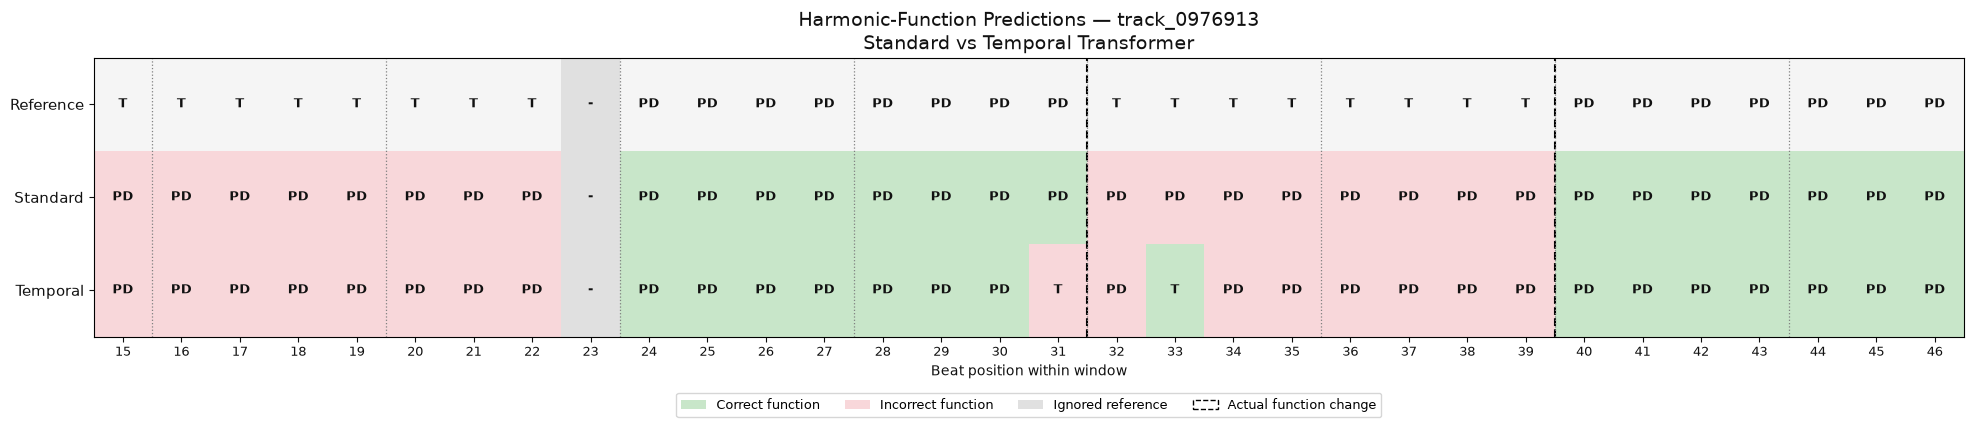


DETAILED PREDICTIONS
-----------------------------------------------------------------


,Beat,Bar,Beat in bar,Reference chord,Reference function,Standard prediction,Temporal prediction
0,15,4,4,VI:MIN,T,PD ✗,PD ✗
1,16,5,1,VI:MIN,T,PD ✗,PD ✗
2,17,5,2,VI:MIN,T,PD ✗,PD ✗
3,18,5,3,VI:MIN,T,PD ✗,PD ✗
4,19,5,4,VI:MIN,T,PD ✗,PD ✗
5,20,6,1,VI:MIN,T,PD ✗,PD ✗
6,21,6,2,VI:MIN,T,PD ✗,PD ✗
7,22,6,3,VI:MIN,T,PD ✗,PD ✗
8,23,6,4,-,-,-,-
9,24,7,1,II:MIN,PD,PD ✓,PD ✓



VISUALIZATION SUMMARY
-----------------------------------------------------------------
Random song: track_0976913
Evaluated beats: 31

Standard Transformer:
  Accuracy: 48.39%
  Macro-F1: 32.61%
  Change-F1: 0.00%

Temporal Transformer:
  Accuracy: 48.39%
  Macro-F1: 37.37%
  Change-F1: 33.33%

Models retrained: NO
Checkpoints modified: NO
Dataset modified: NO
Test dataset accessed: NO

Run again for another random song!


In [89]:
# ============================================================
# RANDOM FUNCTION PREDICTION VISUALIZER
# 284-SONG HIGH-COMPATIBILITY EXPERIMENT
#
# Models:
#  1. Standard 3-function Transformer
#  2. Temporal 3-function Transformer
#
# Original chord labels + function predictions
# Random validation song on every run
# ============================================================

import random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

DISPLAY_BEATS = 32

FUNCTION_SHORT = {
    0: "T",
    1: "PD",
    2: "D"
}

ROMAN_ROOTS = [
    "I", "bII", "II", "bIII",
    "III", "IV", "#IV", "V",
    "bVI", "VI", "bVII", "VII"
]

COLORS = [
    "#F8D7DA",  # Wrong
    "#C8E6C9",  # Correct
    "#E0E0E0",  # Ignored
    "#F5F5F5"   # Reference
]

rng = random.SystemRandom()


# ============================================================
# 2. LOAD BEST CHECKPOINTS
# ============================================================

standard_ckpt = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

temporal_ckpt = torch.load(
    TEMPORAL_BEST_PATH,
    map_location="cpu",
    weights_only=True
)

# Use the same temporal settings as training.

temporal_config = temporal_ckpt["config"]

assert np.isclose(
    TEMPORAL_SIGMA_BEATS,
    temporal_config["temporal_sigma_beats"]
)

assert np.isclose(
    TEMPORAL_STRENGTH,
    temporal_config["temporal_strength"]
)

assert np.isclose(
    TEMPORAL_MAX_PENALTY,
    temporal_config["temporal_max_penalty"]
)

# Separate visualization models so we do not
# modify the training model objects.

viz_standard = FunctionHarmonyTransformer().to(DEVICE)

viz_temporal = TemporalFunctionTransformer().to(DEVICE)

viz_standard.load_state_dict(
    standard_ckpt["model_state_dict"]
)

viz_temporal.load_state_dict(
    temporal_ckpt["model_state_dict"]
)

viz_standard.eval()
viz_temporal.eval()

MODELS = {
    "Standard": viz_standard,
    "Temporal": viz_temporal
}

assert (
    standard_ckpt["selected_tracks"]
    == temporal_ckpt["selected_tracks"]
)


# ============================================================
# 3. GROUP VALIDATION WINDOWS BY SONG
# ============================================================

assert len(val_raw) == len(val_data)

song_windows = defaultdict(list)

for index, window in enumerate(val_raw):

    assert window["split"] == "val"

    # Select windows with at least one
    # reference harmonic-function label.

    has_labels = bool(
        (val_data[index]["target"] != IGNORE_INDEX).any()
    )

    if has_labels:
        song_windows[window["track_id"]].append(index)

all_songs = sorted(song_windows.keys())

assert len(all_songs) > 0


# ============================================================
# 4. SELECT RANDOM SONG WITHOUT REPETITION
# ============================================================

pool_key = "_compat60_function_viz_pool"

remaining = globals().get(pool_key)

if (
    remaining is None
    or not remaining
    or not set(remaining).issubset(set(all_songs))
):

    remaining = all_songs.copy()
    rng.shuffle(remaining)

    globals()[pool_key] = remaining

selected_track = remaining.pop()

selected_index = rng.choice(
    song_windows[selected_track]
)

window = val_raw[selected_index]
sample = val_data[selected_index]

# Single-window model batch.

batch = collate_fn([sample])

batch = {
    key: value.to(DEVICE)
    for key, value in batch.items()
}

targets = sample["target"].cpu()

total_beats = len(targets)


# ============================================================
# 5. SELECT RANDOM EXCERPT
# ============================================================

display_count = min(
    DISPLAY_BEATS,
    total_beats
)

# Prefer an excerpt containing evaluated beats.

valid_starts = [
    s
    for s in range(total_beats - display_count + 1)
    if (
        targets[s:s + display_count] != IGNORE_INDEX
    ).sum().item() > 0
]

assert valid_starts

start = rng.choice(valid_starts)
end = start + display_count

reference = targets[start:end]

valid = reference != IGNORE_INDEX
n_valid = int(valid.sum())


# ============================================================
# 6. GENERATE MODEL PREDICTIONS
# ============================================================

predictions = {}

with torch.inference_mode():

    for name, model in MODELS.items():

        logits = model(batch)

        predictions[name] = (
            logits.argmax(dim=-1)[0]
            .cpu()
        )


# ============================================================
# 7. CALCULATE EXCERPT METRICS
# ============================================================

def evaluate_excerpt(pred, ref, valid):

    y_true = ref[valid]
    y_pred = pred[valid]

    n = len(y_true)

    accuracy = (
        (y_true == y_pred).float().mean().item()
    )

    f1_scores = []
    recalls = {}

    for function_id, function_name in enumerate(
        ["T", "PD", "D"]
    ):

        tp = int((
            (y_true == function_id)
            &
            (y_pred == function_id)
        ).sum())

        support = int(
            (y_true == function_id).sum()
        )

        predicted_count = int(
            (y_pred == function_id).sum()
        )

        if support > 0:

            f1 = (
                2 * tp / (support + predicted_count)
            )

            recall = tp / support

            f1_scores.append(f1)

        else:
            recall = np.nan

        recalls[function_name] = recall

    macro_f1 = (
        float(np.mean(f1_scores))
        if f1_scores else np.nan
    )

    # ----------------------------------------
    # Exact function-change F1
    # ----------------------------------------

    valid_pairs = valid[:-1] & valid[1:]

    true_changes = (
        valid_pairs
        &
        (ref[:-1] != ref[1:])
    )

    predicted_changes = (
        valid_pairs
        &
        (pred[:-1] != pred[1:])
    )

    actual_count = int(true_changes.sum())
    predicted_count = int(predicted_changes.sum())

    detected = int(
        (true_changes & predicted_changes).sum()
    )

    change_f1 = (
        2 * detected / (actual_count + predicted_count)
        if actual_count + predicted_count > 0
        else np.nan
    )

    return {
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
        "Change-F1": change_f1,
        "T recall": recalls["T"],
        "PD recall": recalls["PD"],
        "D recall": recalls["D"],
        "Correct beats": int((y_true == y_pred).sum()),
        "Valid beats": n,
        "Actual changes": actual_count,
        "Predicted changes": predicted_count
    }


result_rows = []

for name in MODELS:

    metrics = evaluate_excerpt(
        predictions[name][start:end],
        reference,
        valid
    )

    result_rows.append({
        "Model": name,
        **metrics
    })

results_df = pd.DataFrame(result_rows)


# ============================================================
# 8. RANDOM SONG SUMMARY
# ============================================================

print("\nRANDOM VALIDATION SONG")
print("-" * 65)

print("Track:", selected_track)
print("Dataset index:", selected_index)

print(
    "Song windows:",
    len(song_windows[selected_track])
)

print(
    "Window index:",
    window["window_index"]
)

print(
    "Displayed beats:",
    f"{start}–{end-1}"
)

print("Valid function beats:", n_valid)

print(
    "Songs visited this cycle:",
    f"{len(all_songs) - len(remaining)}/{len(all_songs)}"
)

print("\nSTANDARD VS TEMPORAL — EXCERPT ACCURACY")
print("-" * 65)

display(results_df.round(4))


# ============================================================
# 9. BUILD VISUALIZATION MATRIX
# ============================================================

ROW_NAMES = [
    "Reference",
    "Standard",
    "Temporal"
]

status_matrix = np.full(
    (3, display_count),
    3,
    dtype=int
)

text_matrix = [
    [""] * display_count
    for _ in range(3)
]

for j in range(display_count):

    i = start + j
    ref = int(targets[i])

    if ref == IGNORE_INDEX:

        text_matrix[0][j] = "-"
        status_matrix[0, j] = 2

        text_matrix[1][j] = "-"
        status_matrix[1, j] = 2

        text_matrix[2][j] = "-"
        status_matrix[2, j] = 2

        continue

    text_matrix[0][j] = FUNCTION_SHORT[ref]

    for row_number, name in enumerate(MODELS, start=1):

        prediction = int(predictions[name][i])

        text_matrix[row_number][j] = (
            FUNCTION_SHORT[prediction]
        )

        status_matrix[row_number, j] = (
            1 if prediction == ref else 0
        )


# ============================================================
# 10. PLOT FUNCTION PREDICTIONS
# ============================================================

fig_width = max(
    17,
    display_count * 0.62
)

fig, ax = plt.subplots(
    figsize=(fig_width, 4.5),
    facecolor="white"
)

ax.set_facecolor("white")

ax.imshow(
    status_matrix,
    cmap=ListedColormap(COLORS),
    vmin=-0.5,
    vmax=3.5,
    aspect="auto",
    interpolation="nearest"
)

for row in range(3):

    for col in range(display_count):

        ax.text(
            col,
            row,
            text_matrix[row][col],
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color="#111111"
        )


# ----------------------------------------
# Actual function changes: BLACK dashed
# ----------------------------------------

for j in range(1, display_count):

    i = start + j

    if (
        targets[i] != IGNORE_INDEX
        and targets[i - 1] != IGNORE_INDEX
        and targets[i] != targets[i - 1]
    ):

        ax.axvline(
            j - 0.5,
            color="black",
            linestyle="--",
            linewidth=1.5
        )


# ----------------------------------------
# Bar boundaries: GRAY dotted
# ----------------------------------------

for j in range(1, display_count):

    i = start + j

    current_bar = window["beat_grid"][i]["bar_index"]
    previous_bar = window["beat_grid"][i - 1]["bar_index"]

    if current_bar != previous_bar:

        ax.axvline(
            j - 0.5,
            color="gray",
            linestyle=":",
            linewidth=0.9
        )


ax.set_yticks(range(3))
ax.set_yticklabels(
    ROW_NAMES,
    fontsize=11,
    color="#111111"
)

ax.set_xticks(range(display_count))

ax.set_xticklabels(
    range(start, end),
    fontsize=9,
    color="#111111"
)

ax.set_xlabel(
    "Beat position within window",
    color="#111111"
)

ax.tick_params(colors="#111111")

ax.set_title(
    f"Harmonic-Function Predictions — {selected_track}\n"
    "Standard vs Temporal Transformer",
    fontsize=14,
    color="#111111"
)

legend = [
    Patch(
        facecolor=COLORS[1],
        label="Correct function"
    ),
    Patch(
        facecolor=COLORS[0],
        label="Incorrect function"
    ),
    Patch(
        facecolor=COLORS[2],
        label="Ignored reference"
    ),
    Patch(
        facecolor="#FFFFFF",
        edgecolor="black",
        linestyle="--",
        label="Actual function change"
    )
]

ax.legend(
    handles=legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=4,
    fontsize=9
)

plt.tight_layout()
plt.show()


# ============================================================
# 11. ORIGINAL ROMAN-NUMERAL CHORD LABELS
# ============================================================

def reference_chord_code(chord):

    if (
        chord.get("target_state") != "CHORD"
        or not chord.get("model_target_mask", 0)
    ):
        return chord.get("plan_label", "-") or "-"

    root = chord.get("root_id")
    family = chord.get("family")

    if root is None or family is None:
        return "-"

    root = int(root)

    if not 0 <= root < 12:
        return "-"

    return f"{ROMAN_ROOTS[root]}:{family}"


# ============================================================
# 12. DETAILED BEAT-BY-BEAT TABLE
# ============================================================

detail_rows = []

for i in range(start, end):

    ref = int(targets[i])

    valid_ref = ref != IGNORE_INDEX

    standard_pred = int(
        predictions["Standard"][i]
    )

    temporal_pred = int(
        predictions["Temporal"][i]
    )

    beat_info = window["beat_grid"][i]
    chord_info = window["beat_targets"][i]

    assert (
        int(beat_info["beat_index"])
        == int(chord_info["beat_index"])
    )

    if valid_ref:

        standard_text = (
            FUNCTION_SHORT[standard_pred]
            +
            (" ✓" if standard_pred == ref else " ✗")
        )

        temporal_text = (
            FUNCTION_SHORT[temporal_pred]
            +
            (" ✓" if temporal_pred == ref else " ✗")
        )

    else:

        standard_text = "-"
        temporal_text = "-"

    detail_rows.append({
        "Beat": i,

        "Bar":
            int(beat_info["bar_index"]) + 1,

        "Beat in bar":
            int(beat_info["beat_in_bar"]),

        "Reference chord":
            reference_chord_code(chord_info),

        "Reference function":
            FUNCTION_SHORT[ref] if valid_ref else "-",

        "Standard prediction":
            standard_text,

        "Temporal prediction":
            temporal_text
    })


detail_df = pd.DataFrame(detail_rows)

print("\nDETAILED PREDICTIONS")
print("-" * 65)

display(detail_df)


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\nVISUALIZATION SUMMARY")
print("-" * 65)

print("Random song:", selected_track)
print("Evaluated beats:", n_valid)

for _, row in results_df.iterrows():

    print(
        f"\n{row['Model']} Transformer:"
    )

    print(
        "  Accuracy:",
        f"{row['Accuracy']:.2%}"
    )

    print(
        "  Macro-F1:",
        f"{row['Macro-F1']:.2%}"
    )

    print(
        "  Change-F1:",
        (
            f"{row['Change-F1']:.2%}"
            if pd.notna(row["Change-F1"])
            else "N/A (no changes)"
        )
    )

print("\nModels retrained: NO")
print("Checkpoints modified: NO")
print("Dataset modified: NO")
print("Test dataset accessed: NO")

print("\nRun again for another random song!")

### BiLSTM Harmonic-Function Baseline

In [90]:
# ============================================================
# PHASE 3 — BIDIRECTIONAL LSTM FUNCTION BASELINE
#
# Same selected 284 songs
# Same input features and 3-function targets
# Same train/validation splits
#
# Architecture:
# Melody embeddings -> BiLSTM encoder
# Beat embeddings   -> BiLSTM beat encoder
# Melody-to-beat cross-attention
# Classification -> T / PD / D
#
# No Gaussian temporal bias
# No genre conditioning
# No previous chord labels
# No test dataset access
# ============================================================

import random
import time
import math

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

LSTM_EXPERIMENT = "function3_compat_both60_bilstm"

LSTM_BEST_PATH = (
    SAVE_DIR / f"{LSTM_EXPERIMENT}_best.pt"
)

LSTM_HISTORY_PATH = (
    SAVE_DIR / f"{LSTM_EXPERIMENT}_history.csv"
)

LSTM_D_MODEL = 128
LSTM_HIDDEN = 64
LSTM_LAYERS = 2
LSTM_DROPOUT = 0.1

LSTM_LR = 3e-4
LSTM_WEIGHT_DECAY = 0.01
LSTM_MAX_EPOCHS = 25
LSTM_PATIENCE = 5

LSTM_GRAD_CLIP = 1.0

LSTM_SEED = 42

random.seed(LSTM_SEED)
np.random.seed(LSTM_SEED)
torch.manual_seed(LSTM_SEED)

assert NUM_FUNCTIONS == 3

print("BIDIRECTIONAL LSTM EXPERIMENT")
print("-" * 65)

print("Experiment:", LSTM_EXPERIMENT)
print("Device:", DEVICE)
print("Training songs:", len(train_tracks))
print("Validation songs:", len(val_tracks))
print("Training windows:", len(train_data))
print("Validation windows:", len(val_data))
print("Output classes:", FUNCTION_NAMES)


# ============================================================
# 2. VERIFY SAME DATASET AND LABELS
# ============================================================

standard_ckpt = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

temporal_ckpt = torch.load(
    TEMPORAL_BEST_PATH,
    map_location="cpu",
    weights_only=True
)

assert (
    set(standard_ckpt["selected_tracks"])
    == set(temporal_ckpt["selected_tracks"])
)

assert (
    set(standard_ckpt["selected_tracks"])
    == set(selected_ids)
)

assert train_tracks.isdisjoint(val_tracks)
assert train_artists.isdisjoint(val_artists)

for dataset in (train_data, val_data):

    for sample in dataset:

        targets = sample["target"]

        assert bool(
            (
                (targets == IGNORE_INDEX)
                |
                (
                    (targets >= 0)
                    & (targets < 3)
                )
            ).all()
        )

print("\nDATASET VERIFICATION")
print("-" * 65)

print("Same selected songs: YES")
print("Same function labels: YES")
print("Artist-disjoint split: YES")
print("Test dataset: NOT ACCESSED")


# ============================================================
# 3. DATA LOADERS
# ============================================================

lstm_generator = torch.Generator().manual_seed(
    LSTM_SEED
)

lstm_train_loader = DataLoader(
    FunctionDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    generator=lstm_generator
)

lstm_val_loader = DataLoader(
    FunctionDataset(val_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

lstm_class_weights = (
    class_weights.detach()
    .clone()
    .to(DEVICE)
)


# ============================================================
# 4. BIDIRECTIONAL LSTM ARCHITECTURE
# ============================================================

class BiLSTMFunctionModel(nn.Module):

    def __init__(self):

        super().__init__()

        # ------------------------------------
        # A. Melody embeddings
        # ------------------------------------

        self.pitch_embedding = nn.Embedding(
            12,
            LSTM_D_MODEL
        )

        self.note_numeric_embedding = nn.Sequential(
            nn.Linear(3, LSTM_D_MODEL),
            nn.GELU(),
            nn.Linear(LSTM_D_MODEL, LSTM_D_MODEL)
        )

        self.note_norm = nn.LayerNorm(
            LSTM_D_MODEL
        )

        # ------------------------------------
        # B. Bidirectional melody encoder
        # ------------------------------------

        self.melody_lstm = nn.LSTM(
            input_size=LSTM_D_MODEL,
            hidden_size=LSTM_HIDDEN,
            num_layers=LSTM_LAYERS,
            batch_first=True,
            bidirectional=True,
            dropout=LSTM_DROPOUT
        )

        # ------------------------------------
        # C. Beat embeddings
        # ------------------------------------

        self.bar_embedding = nn.Embedding(
            32,
            LSTM_D_MODEL
        )

        self.position_embedding = nn.Embedding(
            17,
            LSTM_D_MODEL
        )

        self.meter_embedding = nn.Embedding(
            17,
            LSTM_D_MODEL
        )

        self.beat_numeric_embedding = nn.Sequential(
            nn.Linear(2, LSTM_D_MODEL),
            nn.GELU(),
            nn.Linear(LSTM_D_MODEL, LSTM_D_MODEL)
        )

        self.beat_norm = nn.LayerNorm(
            LSTM_D_MODEL
        )

        # ------------------------------------
        # D. Bidirectional beat encoder
        # ------------------------------------

        self.beat_lstm = nn.LSTM(
            input_size=LSTM_D_MODEL,
            hidden_size=LSTM_HIDDEN,
            num_layers=LSTM_LAYERS,
            batch_first=True,
            bidirectional=True,
            dropout=LSTM_DROPOUT
        )

        # ------------------------------------
        # E. Melody-to-beat attention
        # ------------------------------------

        # Both BiLSTMs output:
        # 64 forward + 64 backward = 128 features

        self.query_projection = nn.Linear(
            LSTM_D_MODEL,
            LSTM_D_MODEL
        )

        self.key_projection = nn.Linear(
            LSTM_D_MODEL,
            LSTM_D_MODEL
        )

        self.value_projection = nn.Linear(
            LSTM_D_MODEL,
            LSTM_D_MODEL
        )

        self.attention_dropout = nn.Dropout(
            LSTM_DROPOUT
        )

        # ------------------------------------
        # F. Function classifier
        # ------------------------------------

        self.classifier = nn.Sequential(
            nn.Linear(
                LSTM_D_MODEL * 2,
                LSTM_D_MODEL
            ),
            nn.LayerNorm(LSTM_D_MODEL),
            nn.GELU(),
            nn.Dropout(LSTM_DROPOUT),
            nn.Linear(
                LSTM_D_MODEL,
                NUM_FUNCTIONS
            )
        )

    def encode_lstm(
        self,
        embeddings,
        padding_mask,
        lstm
    ):

        lengths = (
            (~padding_mask)
            .sum(dim=1)
            .cpu()
        )

        packed = pack_padded_sequence(
            embeddings,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, _ = lstm(packed)

        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=embeddings.shape[1]
        )

        return outputs

    def forward(self, batch):

        # ====================================
        # 1. Encode melody notes
        # ====================================

        note_embeddings = (
            self.pitch_embedding(
                batch["note_pc"]
            )
            +
            self.note_numeric_embedding(
                batch["note_numeric"]
            )
        )

        note_embeddings = self.note_norm(
            note_embeddings
        )

        melody_states = self.encode_lstm(
            note_embeddings,
            batch["note_pad"],
            self.melody_lstm
        )

        # ====================================
        # 2. Encode beat positions
        # ====================================

        beat_embeddings = (
            self.bar_embedding(
                batch["bar"].clamp(0, 31)
            )
            +
            self.position_embedding(
                batch["position"].clamp(0, 16)
            )
            +
            self.meter_embedding(
                batch["meter"].clamp(0, 16)
            )
            +
            self.beat_numeric_embedding(
                batch["beat_numeric"]
            )
        )

        beat_embeddings = self.beat_norm(
            beat_embeddings
        )

        beat_states = self.encode_lstm(
            beat_embeddings,
            batch["beat_pad"],
            self.beat_lstm
        )

        # ====================================
        # 3. Cross-attention
        # ====================================

        # Beat queries attend to melody states.

        Q = self.query_projection(
            beat_states
        )

        K = self.key_projection(
            melody_states
        )

        V = self.value_projection(
            melody_states
        )

        # Shape: [batch, beats, notes]

        attention_scores = (
            torch.bmm(
                Q,
                K.transpose(1, 2)
            )
            /
            math.sqrt(LSTM_D_MODEL)
        )

        # Hide padded melody notes.

        attention_scores = (
            attention_scores.masked_fill(
                batch["note_pad"].unsqueeze(1),
                -1e4
            )
        )

        attention_weights = F.softmax(
            attention_scores,
            dim=-1
        )

        attention_weights = (
            self.attention_dropout(
                attention_weights
            )
        )

        melody_context = torch.bmm(
            attention_weights,
            V
        )

        # ====================================
        # 4. Combine melody and beat states
        # ====================================

        combined = torch.cat(
            [
                beat_states,
                melody_context
            ],
            dim=-1
        )

        # ====================================
        # 5. Predict harmonic functions
        # ====================================

        logits = self.classifier(
            combined
        )

        return logits


# ============================================================
# 5. INITIALIZE MODEL
# ============================================================

lstm_model = BiLSTMFunctionModel().to(
    DEVICE
)

lstm_parameters = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

standard_parameters = sum(
    p.numel()
    for p in standard_ckpt["model_state_dict"].values()
)

print("\nMODEL ARCHITECTURE")
print("-" * 65)

print("Architecture: Bidirectional LSTM")
print("Melody BiLSTM layers:", LSTM_LAYERS)
print("Beat BiLSTM layers:", LSTM_LAYERS)
print("Hidden size per direction:", LSTM_HIDDEN)
print("Cross-attention: YES")
print("Gaussian temporal bias: NO")

print("\nStandard Transformer parameters:",
      f"{standard_parameters:,}")

print("BiLSTM parameters:",
      f"{lstm_parameters:,}")


# ============================================================
# 6. VERIFY FORWARD PASS
# ============================================================

probe = next(
    iter(lstm_train_loader)
)

probe = {
    k: v.to(DEVICE)
    for k, v in probe.items()
}

lstm_model.eval()

with torch.no_grad():

    probe_logits = lstm_model(
        probe
    )

assert probe_logits.shape == (
    probe["target"].shape[0],
    probe["target"].shape[1],
    NUM_FUNCTIONS
)

assert torch.isfinite(
    probe_logits
).all()

print("\nForward-pass verification: PASSED")


# ============================================================
# 7. OPTIMIZER
# ============================================================

lstm_optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=LSTM_LR,
    weight_decay=LSTM_WEIGHT_DECAY
)


# ============================================================
# 8. TRAINING
# ============================================================

def lstm_train_epoch():

    lstm_model.train()

    weighted_loss_total = 0.0
    weight_total = 0.0

    for batch in lstm_train_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]

        valid = targets != IGNORE_INDEX

        if not bool(valid.any()):
            continue

        lstm_optimizer.zero_grad(
            set_to_none=True
        )

        logits = lstm_model(
            batch
        )

        loss = F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            targets.reshape(-1),
            weight=lstm_class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=LSTM_GRAD_CLIP
        )

        lstm_optimizer.step()

        batch_weight = (
            lstm_class_weights[targets[valid]]
            .sum().item()
        )

        weighted_loss_total += (
            loss.item() * batch_weight
        )

        weight_total += batch_weight

    return (
        weighted_loss_total / weight_total
    )


# ============================================================
# 9. VALIDATION
# ============================================================

@torch.inference_mode()
def lstm_validate():

    lstm_model.eval()

    confusion = torch.zeros(
        NUM_FUNCTIONS,
        NUM_FUNCTIONS,
        dtype=torch.long
    )

    total_loss = 0.0
    total_beats = 0

    actual_changes = 0
    predicted_changes = 0
    correctly_detected = 0

    correct_transition_pairs = 0
    valid_pairs = 0

    for batch in lstm_val_loader:

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        targets = batch["target"]

        valid = (
            targets != IGNORE_INDEX
        )

        logits = lstm_model(
            batch
        )

        predictions = logits.argmax(
            dim=-1
        )

        # ------------------------------------
        # Classification loss
        # ------------------------------------

        total_loss += F.cross_entropy(
            logits.reshape(-1, NUM_FUNCTIONS),
            targets.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        ).item()

        total_beats += int(
            valid.sum()
        )

        y_true = targets[valid]
        y_pred = predictions[valid]

        indices = (
            y_true * NUM_FUNCTIONS + y_pred
        )

        confusion += torch.bincount(
            indices,
            minlength=NUM_FUNCTIONS ** 2
        ).reshape(
            NUM_FUNCTIONS,
            NUM_FUNCTIONS
        ).cpu()

        # ------------------------------------
        # Function-change metrics
        # ------------------------------------

        pair_valid = (
            valid[:, :-1]
            &
            valid[:, 1:]
        )

        true_change = (
            pair_valid
            &
            (
                targets[:, :-1]
                != targets[:, 1:]
            )
        )

        pred_change = (
            pair_valid
            &
            (
                predictions[:, :-1]
                != predictions[:, 1:]
            )
        )

        actual_changes += int(
            true_change.sum()
        )

        predicted_changes += int(
            pred_change.sum()
        )

        correctly_detected += int(
            (
                true_change
                &
                pred_change
            ).sum()
        )

        valid_pairs += int(
            pair_valid.sum()
        )

        correct_transition_pairs += int(
            (
                true_change
                &
                (
                    predictions[:, :-1]
                    == targets[:, :-1]
                )
                &
                (
                    predictions[:, 1:]
                    == targets[:, 1:]
                )
            ).sum()
        )

    # ----------------------------------------
    # Per-class metrics
    # ----------------------------------------

    tp = confusion.diag().float()

    support = (
        confusion.sum(dim=1).float()
    )

    predicted_support = (
        confusion.sum(dim=0).float()
    )

    precision = (
        tp / predicted_support.clamp(min=1)
    )

    recall = (
        tp / support.clamp(min=1)
    )

    f1 = (
        2 * tp /
        (
            support + predicted_support
        ).clamp(min=1)
    )

    accuracy = (
        tp.sum().item() / total_beats
    )

    macro_f1 = (
        f1.mean().item()
    )

    change_precision = (
        correctly_detected / predicted_changes
        if predicted_changes else 0.0
    )

    change_recall = (
        correctly_detected / actual_changes
        if actual_changes else 0.0
    )

    change_f1 = (
        2 * correctly_detected /
        max(
            1,
            actual_changes + predicted_changes
        )
    )

    transition_pair_accuracy = (
        correct_transition_pairs /
        max(1, actual_changes)
    )

    return {
        "val_loss":
            total_loss / total_beats,

        "accuracy": accuracy,
        "macro_f1": macro_f1,

        "change_precision": change_precision,
        "change_recall": change_recall,
        "change_f1": change_f1,

        "transition_pair_accuracy":
            transition_pair_accuracy,

        "true_change_rate":
            actual_changes / max(1, valid_pairs),

        "predicted_change_rate":
            predicted_changes / max(1, valid_pairs),

        "valid_beats": total_beats,
        "valid_pairs": valid_pairs,
        "actual_changes": actual_changes,

        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),

        "support": support.long().tolist(),
        "confusion": confusion.tolist()
    }


# ============================================================
# 10. TRAINING LOOP
# ============================================================

lstm_history = []

lstm_best_loss = float("inf")
lstm_best_epoch = None

lstm_patience_counter = 0

print("\nBIDIRECTIONAL LSTM TRAINING STARTED")
print("=" * 95)

for epoch in range(
    1,
    LSTM_MAX_EPOCHS + 1
):

    t0 = time.perf_counter()

    train_loss = lstm_train_epoch()

    metrics = lstm_validate()

    elapsed = time.perf_counter() - t0

    lstm_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": metrics["val_loss"],
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "change_f1": metrics["change_f1"],
        "transition_pair_accuracy":
            metrics["transition_pair_accuracy"],
        "true_change_rate":
            metrics["true_change_rate"],
        "predicted_change_rate":
            metrics["predicted_change_rate"],
        "seconds": elapsed
    })

    improved = (
        metrics["val_loss"]
        < lstm_best_loss - 1e-4
    )

    if improved:

        lstm_best_loss = metrics["val_loss"]
        lstm_best_epoch = epoch

        lstm_patience_counter = 0

        torch.save({
            "epoch": epoch,

            "model_state_dict":
                lstm_model.state_dict(),

            "optimizer_state_dict":
                lstm_optimizer.state_dict(),

            "metrics": metrics,

            "selected_tracks":
                sorted(selected_ids),

            "experiment": LSTM_EXPERIMENT,
            "seed": LSTM_SEED,

            "config": {
                "d_model": LSTM_D_MODEL,
                "hidden_size": LSTM_HIDDEN,
                "layers": LSTM_LAYERS,
                "dropout": LSTM_DROPOUT,
                "num_classes": NUM_FUNCTIONS,
                "bidirectional": True,
                "cross_attention": True,
                "temporal_bias": False,
                "genre_conditioning": False
            }
        }, LSTM_BEST_PATH)

    else:

        lstm_patience_counter += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.4f} | "
        f"Val {metrics['val_loss']:.4f} | "
        f"Acc {metrics['accuracy']:.4f} | "
        f"Macro-F1 {metrics['macro_f1']:.4f} | "
        f"Change-F1 {metrics['change_f1']:.4f} | "
        f"PredChange {metrics['predicted_change_rate']:.4f} | "
        f"{elapsed:.1f}s"
        +
        (" | BEST" if improved else "")
    )

    if (
        lstm_patience_counter
        >= LSTM_PATIENCE
    ):

        print(
            f"\nEarly stopping at epoch {epoch}"
        )

        break


# ============================================================
# 11. LOAD BEST MODEL
# ============================================================

lstm_checkpoint = torch.load(
    LSTM_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

lstm_model.load_state_dict(
    lstm_checkpoint["model_state_dict"]
)

lstm_best_metrics = lstm_validate()

lstm_history_df = pd.DataFrame(
    lstm_history
)

lstm_history_df.to_csv(
    LSTM_HISTORY_PATH,
    index=False
)

print("\nTRAINING HISTORY")
print("-" * 65)

display(
    lstm_history_df.round(4)
)


# ============================================================
# 12. COMPARE ALL THREE MODELS
# ============================================================

standard_metrics = standard_ckpt["metrics"]
temporal_metrics = temporal_ckpt["metrics"]

comparison_rows = []

for name, m in [
    ("Standard Transformer", standard_metrics),
    ("Temporal Transformer", temporal_metrics),
    ("Bidirectional LSTM", lstm_best_metrics)
]:

    comparison_rows.append({
        "Model": name,
        "Function accuracy": m["accuracy"],
        "Macro-F1": m["macro_f1"],
        "Change-F1": m["change_f1"],
        "Transition-pair accuracy":
            m["transition_pair_accuracy"],
        "Validation loss": m["val_loss"]
    })

lstm_comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nTHREE-MODEL COMPARISON")
print("=" * 85)

display(
    lstm_comparison_df.round(4)
)


# ============================================================
# 13. PER-FUNCTION COMPARISON
# ============================================================

class_rows = []

for model_name, metrics in [
    ("Standard", standard_metrics),
    ("Temporal", temporal_metrics),
    ("BiLSTM", lstm_best_metrics)
]:

    for i, function in enumerate(FUNCTION_NAMES):

        class_rows.append({
            "Model": model_name,
            "Function": function,
            "Reference beats":
                metrics["support"][i],
            "Precision":
                metrics["precision"][i],
            "Recall":
                metrics["recall"][i],
            "F1":
                metrics["f1"][i]
        })

lstm_per_function_df = pd.DataFrame(
    class_rows
)

print("\nPER-FUNCTION COMPARISON")
print("-" * 85)

display(
    lstm_per_function_df.round(4)
)


# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

lstm_confusion_df = pd.DataFrame(
    lstm_best_metrics["confusion"],
    index=FUNCTION_NAMES,
    columns=FUNCTION_NAMES
)

lstm_confusion_df.index.name = "Actual"
lstm_confusion_df.columns.name = "Predicted"

print("\nBILSTM CONFUSION MATRIX")
print("-" * 65)

display(lstm_confusion_df)


# ============================================================
# 15. TRANSITION COMPARISON
# ============================================================

transition_rows = []

for name, m in [
    ("Standard Transformer", standard_metrics),
    ("Temporal Transformer", temporal_metrics),
    ("BiLSTM", lstm_best_metrics)
]:

    transition_rows.append({
        "Model": name,
        "Actual change rate":
            m["true_change_rate"],
        "Predicted change rate":
            m["predicted_change_rate"],
        "Change-F1":
            m["change_f1"],
        "Transition-pair accuracy":
            m["transition_pair_accuracy"]
    })

lstm_transition_df = pd.DataFrame(
    transition_rows
)

print("\nTRANSITION COMPARISON")
print("-" * 85)

display(
    lstm_transition_df.round(4)
)


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\nBEST BIDIRECTIONAL LSTM")
print("=" * 65)

print("Best epoch:", lstm_best_epoch)

print(
    "Function accuracy:",
    f"{lstm_best_metrics['accuracy']:.2%}"
)

print(
    "Macro-F1:",
    f"{lstm_best_metrics['macro_f1']:.2%}"
)

print(
    "Change-F1:",
    f"{lstm_best_metrics['change_f1']:.2%}"
)

print(
    "Transition-pair accuracy:",
    f"{lstm_best_metrics['transition_pair_accuracy']:.2%}"
)

print(
    "Validation loss:",
    round(lstm_best_metrics["val_loss"], 4)
)

print(
    "Evaluated function beats:",
    lstm_best_metrics["valid_beats"]
)

print(
    "\nCheckpoint:",
    LSTM_BEST_PATH
)

print(
    "\nHistory:",
    LSTM_HISTORY_PATH
)

print("\nVERIFICATION")
print("-" * 65)

print("Standard checkpoint overwritten: NO")
print("Temporal checkpoint overwritten: NO")
print("Dataset modified: NO")
print("Artist-disjoint split preserved: YES")
print("Test dataset accessed: NO")

print("\nBILSTM EXPERIMENT COMPLETED!")

BIDIRECTIONAL LSTM EXPERIMENT
-----------------------------------------------------------------
Experiment: function3_compat_both60_bilstm
Device: cpu
Training songs: 243
Validation songs: 41
Training windows: 1977
Validation windows: 398
Output classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']

DATASET VERIFICATION
-----------------------------------------------------------------
Same selected songs: YES
Same function labels: YES
Artist-disjoint split: YES
Test dataset: NOT ACCESSED

MODEL ARCHITECTURE
-----------------------------------------------------------------
Architecture: Bidirectional LSTM
Melody BiLSTM layers: 2
Beat BiLSTM layers: 2
Hidden size per direction: 64
Cross-attention: YES
Gaussian temporal bias: NO

Standard Transformer parameters: 970,499
BiLSTM parameters: 524,803

Forward-pass verification: PASSED

BIDIRECTIONAL LSTM TRAINING STARTED
Epoch 01 | Train 0.9951 | Val 0.9075 | Acc 0.6000 | Macro-F1 0.4691 | Change-F1 0.0302 | PredChange 0.0133 | 13.8s | BEST
Epoch 02 

,epoch,train_loss,val_loss,accuracy,macro_f1,change_f1,transition_pair_accuracy,true_change_rate,predicted_change_rate,seconds
0,1,0.9951,0.9075,0.6000,0.4691,0.0302,0.0054,0.0595,0.0133,13.8439
1,2,0.9634,0.9381,0.5485,0.4685,0.0319,0.0033,0.0595,0.0135,12.7784
2,3,0.9534,0.9317,0.5782,0.4645,0.0236,0.0033,0.0595,0.0116,12.4813
3,4,0.9448,0.9528,0.5729,0.4734,0.0252,0.0022,0.0595,0.0174,12.9024
4,5,0.9360,0.8964,0.6014,0.4746,0.0295,0.0054,0.0595,0.0149,12.5893
5,6,0.9285,0.9210,0.5993,0.4803,0.0228,0.0011,0.0595,0.0144,12.4421
6,7,0.9158,0.9236,0.5906,0.4700,0.0386,0.0065,0.0595,0.0176,12.6036
7,8,0.9071,0.9609,0.5592,0.4660,0.0494,0.0054,0.0595,0.0269,12.5195
8,9,0.8954,0.9374,0.5849,0.4629,0.0442,0.0087,0.0595,0.0253,12.6361
9,10,0.8862,0.9273,0.5922,0.4365,0.0246,0.0043,0.0595,0.0140,12.5944



THREE-MODEL COMPARISON


,Model,Function accuracy,Macro-F1,Change-F1,Transition-pair accuracy,Validation loss
0,Standard Transformer,0.6107,0.4772,0.0764,0.0217,0.8907
1,Temporal Transformer,0.6306,0.5443,0.1237,0.0609,0.8447
2,Bidirectional LSTM,0.6014,0.4746,0.0295,0.0054,0.8964



PER-FUNCTION COMPARISON
-------------------------------------------------------------------------------------


...


BILSTM CONFUSION MATRIX
-----------------------------------------------------------------


Predicted,TONIC,PREDOMINANT,DOMINANT
Actual,,,
TONIC,7664,1641,623
PREDOMINANT,2771,2623,207
DOMINANT,1322,487,351



TRANSITION COMPARISON
-------------------------------------------------------------------------------------


,Model,Actual change rate,Predicted change rate,Change-F1,Transition-pair accuracy
0,Standard Transformer,0.0595,0.0455,0.0764,0.0217
1,Temporal Transformer,0.0595,0.1037,0.1237,0.0609
2,BiLSTM,0.0595,0.0149,0.0295,0.0054



BEST BIDIRECTIONAL LSTM
Best epoch: 5
Function accuracy: 60.14%
Macro-F1: 47.46%
Change-F1: 2.95%
Transition-pair accuracy: 0.54%
Validation loss: 0.8964
Evaluated function beats: 17689

Checkpoint: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/function3_compat_both60_bilstm_best.pt

History: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/function3_compat_both60_bilstm_history.csv

VERIFICATION
-----------------------------------------------------------------
Standard checkpoint overwritten: NO
Temporal checkpoint overwritten: NO
Dataset modified: NO
Artist-disjoint split preserved: YES
Test dataset accessed: NO

BILSTM EXPERIMENT COMPLETED!
